# Tuần 10 — Khái quát dữ liệu (6/7): Bootstrap và mở đầu kiểm định

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Một nhóm kỹ thuật lấy ngẫu nhiên 100 linh kiện và thấy 62 linh kiện đạt chuẩn tiết kiệm điện. Họ có hai câu hỏi:

1. Tỉ lệ đạt của cả lô khoảng bao nhiêu, và con số 0,62 có thể sai đến đâu? Nhóm chỉ có **một** mẫu và không muốn dựa vào công thức.
2. Nếu tỉ lệ đạt thật chỉ là 50% như mức chuẩn cũ, thì thấy 62/100 có phải chuyện hiếm không?

Câu 1 dẫn đến **bootstrap**, câu 2 dẫn đến **kiểm định giả thuyết**. Cả hai đều dựng một phân phối cho thống kê, nhưng dựng từ hai nơi khác nhau.

### Sau buổi này, bạn làm được

- dùng bootstrap (lấy mẫu lại có hoàn lại) để ước lượng sai số chuẩn và lập khoảng tin cậy theo phân vị;
- giải thích vì sao bootstrap phải lấy có hoàn lại, và bootstrap không sửa được gì;
- thực hiện đủ sáu bước của một kiểm định: đơn vị và dữ liệu, $H_0$ và $H_A$, thống kê, phân phối dưới $H_0$, giá trị p, kết luận;
- tính giá trị p chính xác bằng phân phối nhị thức và siêu bội; so với xấp xỉ chuẩn và mô phỏng;
- lập kiểm định ngẫu nhiên hóa (gán lại nhãn) cho thí nghiệm hai nhóm, đúng với cơ chế gán của thiết kế;
- diễn giải đúng giá trị p và nêu giới hạn khi dữ liệu là quan sát.

Nội dung đáp ứng **LLO10.1/CLO3** của đề cương.

### Cần nhớ từ các buổi trước

- **Phân phối nhị thức** (Tuần 06). $K\sim\operatorname{Binomial}(n, p)$: $P(K=k)=\binom nk p^k(1-p)^{n-k}$, $E(K)=np$, $\mathrm{SD}(K)=\sqrt{np(1-p)}$.
- **Phân phối siêu bội** (Tuần 06). Rút không hoàn lại $n$ phần tử từ $N$ phần tử có $D$ phần tử “thành công”: $P(K=k)=\binom Dk\binom{N-D}{n-k}\big/\binom Nn$.
- **Tổ hợp** (Tuần 06). Số cách chọn $k$ phần tử từ $n$ là $\binom nk$; ví dụ $\binom{12}6=924$.
- **Sai số chuẩn và khoảng tin cậy** (Tuần 09). $SE(\hat p)=\sqrt{p(1-p)/n}$; khoảng 95% có dạng ước lượng $\pm$ 1,96 SE.
- **Phân vị** (Tuần 02). Phân vị mức 2,5% là giá trị mà 2,5% dữ liệu nhỏ hơn nó.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–3: bootstrap, sai số chuẩn bootstrap, sáu bước kiểm định với 100 linh kiện. Mục 4: thí nghiệm 12 cảm biến. |
| Tự luyện | Bài hai giả thuyết đối, 20 linh kiện, bo mạch hai dây chuyền, 6 thiết bị; mục 5–6: Kristen Gilbert và các bài toán tổng hợp. |
| Đọc sâu | Khối **Vì sao?**: phân phối bootstrap của tỉ lệ; vì sao không lấy không hoàn lại; phân phối siêu bội từ phép gán; giới hạn của mô phỏng khi p rất nhỏ. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Bootstrap tạo mẫu thay thế từ mẫu đang có](#muc-1) · [2. Từ phân phối bootstrap đến sai số chuẩn và khoảng phân vị](#muc-2) · [3. Kiểm định đặt ra một thế giới giả định khác](#muc-3) · [4. Gán lại nhóm phải giữ đúng thiết kế](#muc-4) · [5. Kristen Gilbert: kiểm định mô hình liên hệ có điều kiện](#muc-5) · [6. Bài toán tổng hợp: tính đúng chưa đủ để kết luận đúng](#muc-6)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| $T$, $t_{obs}$ | T, t quan sát | thống kê (quy tắc tính) và giá trị tính được từ dữ liệu thật | $t_{obs}=0{,}62$ |
| $T^*_b$ | T sao b | thống kê tính trên mẫu bootstrap thứ $b$ | $\hat p^*_1=0{,}6$ |
| $B$ | B | số lần lấy mẫu lại (hay số lần mô phỏng) | $B=20\,000$ |
| $E^*$, $P^*$, $SE^*$ | E sao, P sao | kỳ vọng, xác suất, SE **khi giữ mẫu gốc cố định** và chỉ lấy mẫu lại | $E^*(\hat p^*)=\hat p$ |
| $q^*_a$ | q sao a | phân vị mức $a$ của các $T^*_b$ | $q^*_{0{,}025}\approx0{,}52$ |
| $H_0$, $H_A$ | H không, H A | giả thuyết không và giả thuyết đối | $H_0: p=0{,}5$, $H_A: p>0{,}5$ |
| $p_0$ | p không | tỉ lệ được giả định trong $H_0$ | $p_0=0{,}5$ |
| $P_{H_0}(\cdot)$ | xác suất dưới H không | xác suất tính với giả định $H_0$ đúng | $P_{H_0}(K\ge62)\approx0{,}0105$ |
| $\alpha$ | an-pha | mức ý nghĩa: ngưỡng chọn trước để quyết định | $\alpha=0{,}05$ |
| $\hat p_A-\hat p_B$ | p mũ A trừ p mũ B | chênh lệch tỉ lệ giữa hai nhóm | $5/6-2/6=0{,}5$ |
| $\binom nk$ | tổ hợp chập k của n | số cách chọn $k$ phần tử từ $n$ | $\binom63=20$ |

**Dấu sao.** Mọi thứ có dấu $^*$ thuộc về thế giới lấy mẫu lại: mẫu gốc đã cố định, chỉ có việc rút lại là ngẫu nhiên. Đừng nhầm $SE^*$ (tính từ mẫu đã thấy) với SE thật của tổng thể.

**Hai tỉ lệ dễ lẫn.** $\hat p=0{,}62$ là tỉ lệ đã **quan sát**; $p_0=0{,}50$ là tỉ lệ được **giả định** trong $H_0$. Bootstrap dùng $\hat p$; kiểm định dùng $p_0$.

### Thiết lập tính toán

- `numpy`, `pandas`, `scipy.stats` như Tuần 09. Tuần này dùng thêm `stats.binom` (nhị thức), `stats.hypergeom` (siêu bội), `stats.binomtest` (kiểm định nhị thức chính xác) và `itertools.combinations` (liệt kê mọi cách chọn).
- `DATA = Path('datasets')`: chứa `kristen_gilbert_reconstructed.csv` dùng ở mục 5.
- `rng` với seed 42 dùng chung. Một số ô có **seed riêng** (20261010, 20261011, 20261101) để cho đúng các con số trên slide; khi chạy lại từ đầu, kết quả sẽ khớp với chữ trong bài.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

<a id="muc-1"></a>

## 1. Bootstrap tạo mẫu thay thế từ mẫu đang có

### Vấn đề

Ở Tuần 09, ta hiểu sai số chuẩn bằng cách **tưởng tượng** lấy hàng nghìn mẫu mới từ tổng thể. Với trung bình và tỉ lệ có công thức sẵn. Nhưng:

- với trung vị, phân vị, hệ số tương quan, hệ số hồi quy..., phân phối mẫu khó tính bằng công thức;
- trong thực tế ta chỉ có **một** mẫu, không thể đi lấy thêm hàng nghìn mẫu.

### Ý tưởng bootstrap

Mẫu đã có là hình ảnh thu nhỏ tốt nhất của tổng thể mà ta biết. Bootstrap coi mẫu như một "tổng thể thay thế" rồi lặp lại việc lấy mẫu **từ chính nó**.

Với mẫu $x_1,\ldots, x_n$ và thống kê $T$:

1. Coi mỗi **vị trí** trong mẫu có khả năng được chọn như nhau, $1/n$.
2. Rút $n$ lần **có hoàn lại** từ các vị trí ấy: được một *mẫu bootstrap* cỡ $n$.
3. Tính lại thống kê trên mẫu bootstrap, gọi là $T^*$.
4. Lặp $B$ lần. Các giá trị $T^*_1,\ldots, T^*_B$ tạo thành **phân phối bootstrap**.

Độ phân tán của phân phối bootstrap là ước lượng cho độ phân tán của $T$ qua các mẫu thật.

**Mẫu bootstrap không phải mẫu mới từ tổng thể.** Nó chỉ sắp xếp lại thông tin trong $n$ quan sát đã có; nó không thêm được thông tin nào về những đơn vị ngoài mẫu.
<details><summary><b>Vì sao?</b> phải lấy có hoàn lại</summary>

Nếu rút **không hoàn lại** đủ $n$ vị trí từ mẫu có $n$ vị trí, ta chỉ được đúng mẫu cũ với thứ tự khác. Trung bình, tỉ lệ, trung vị đều không phụ thuộc thứ tự, nên $T^*$ luôn bằng $T$: phân phối bootstrap chỉ có một giá trị, SE bằng 0.

Rút **có hoàn lại** thì một quan sát có thể xuất hiện nhiều lần, quan sát khác có thể vắng mặt. Xác suất một quan sát cụ thể vắng mặt trong một mẫu bootstrap là $(1-1/n)^n$, gần $e^{-1}\approx0{,}37$ khi $n$ lớn. Nhờ vậy mỗi mẫu bootstrap khác nhau, và $T^*$ dao động.

</details>

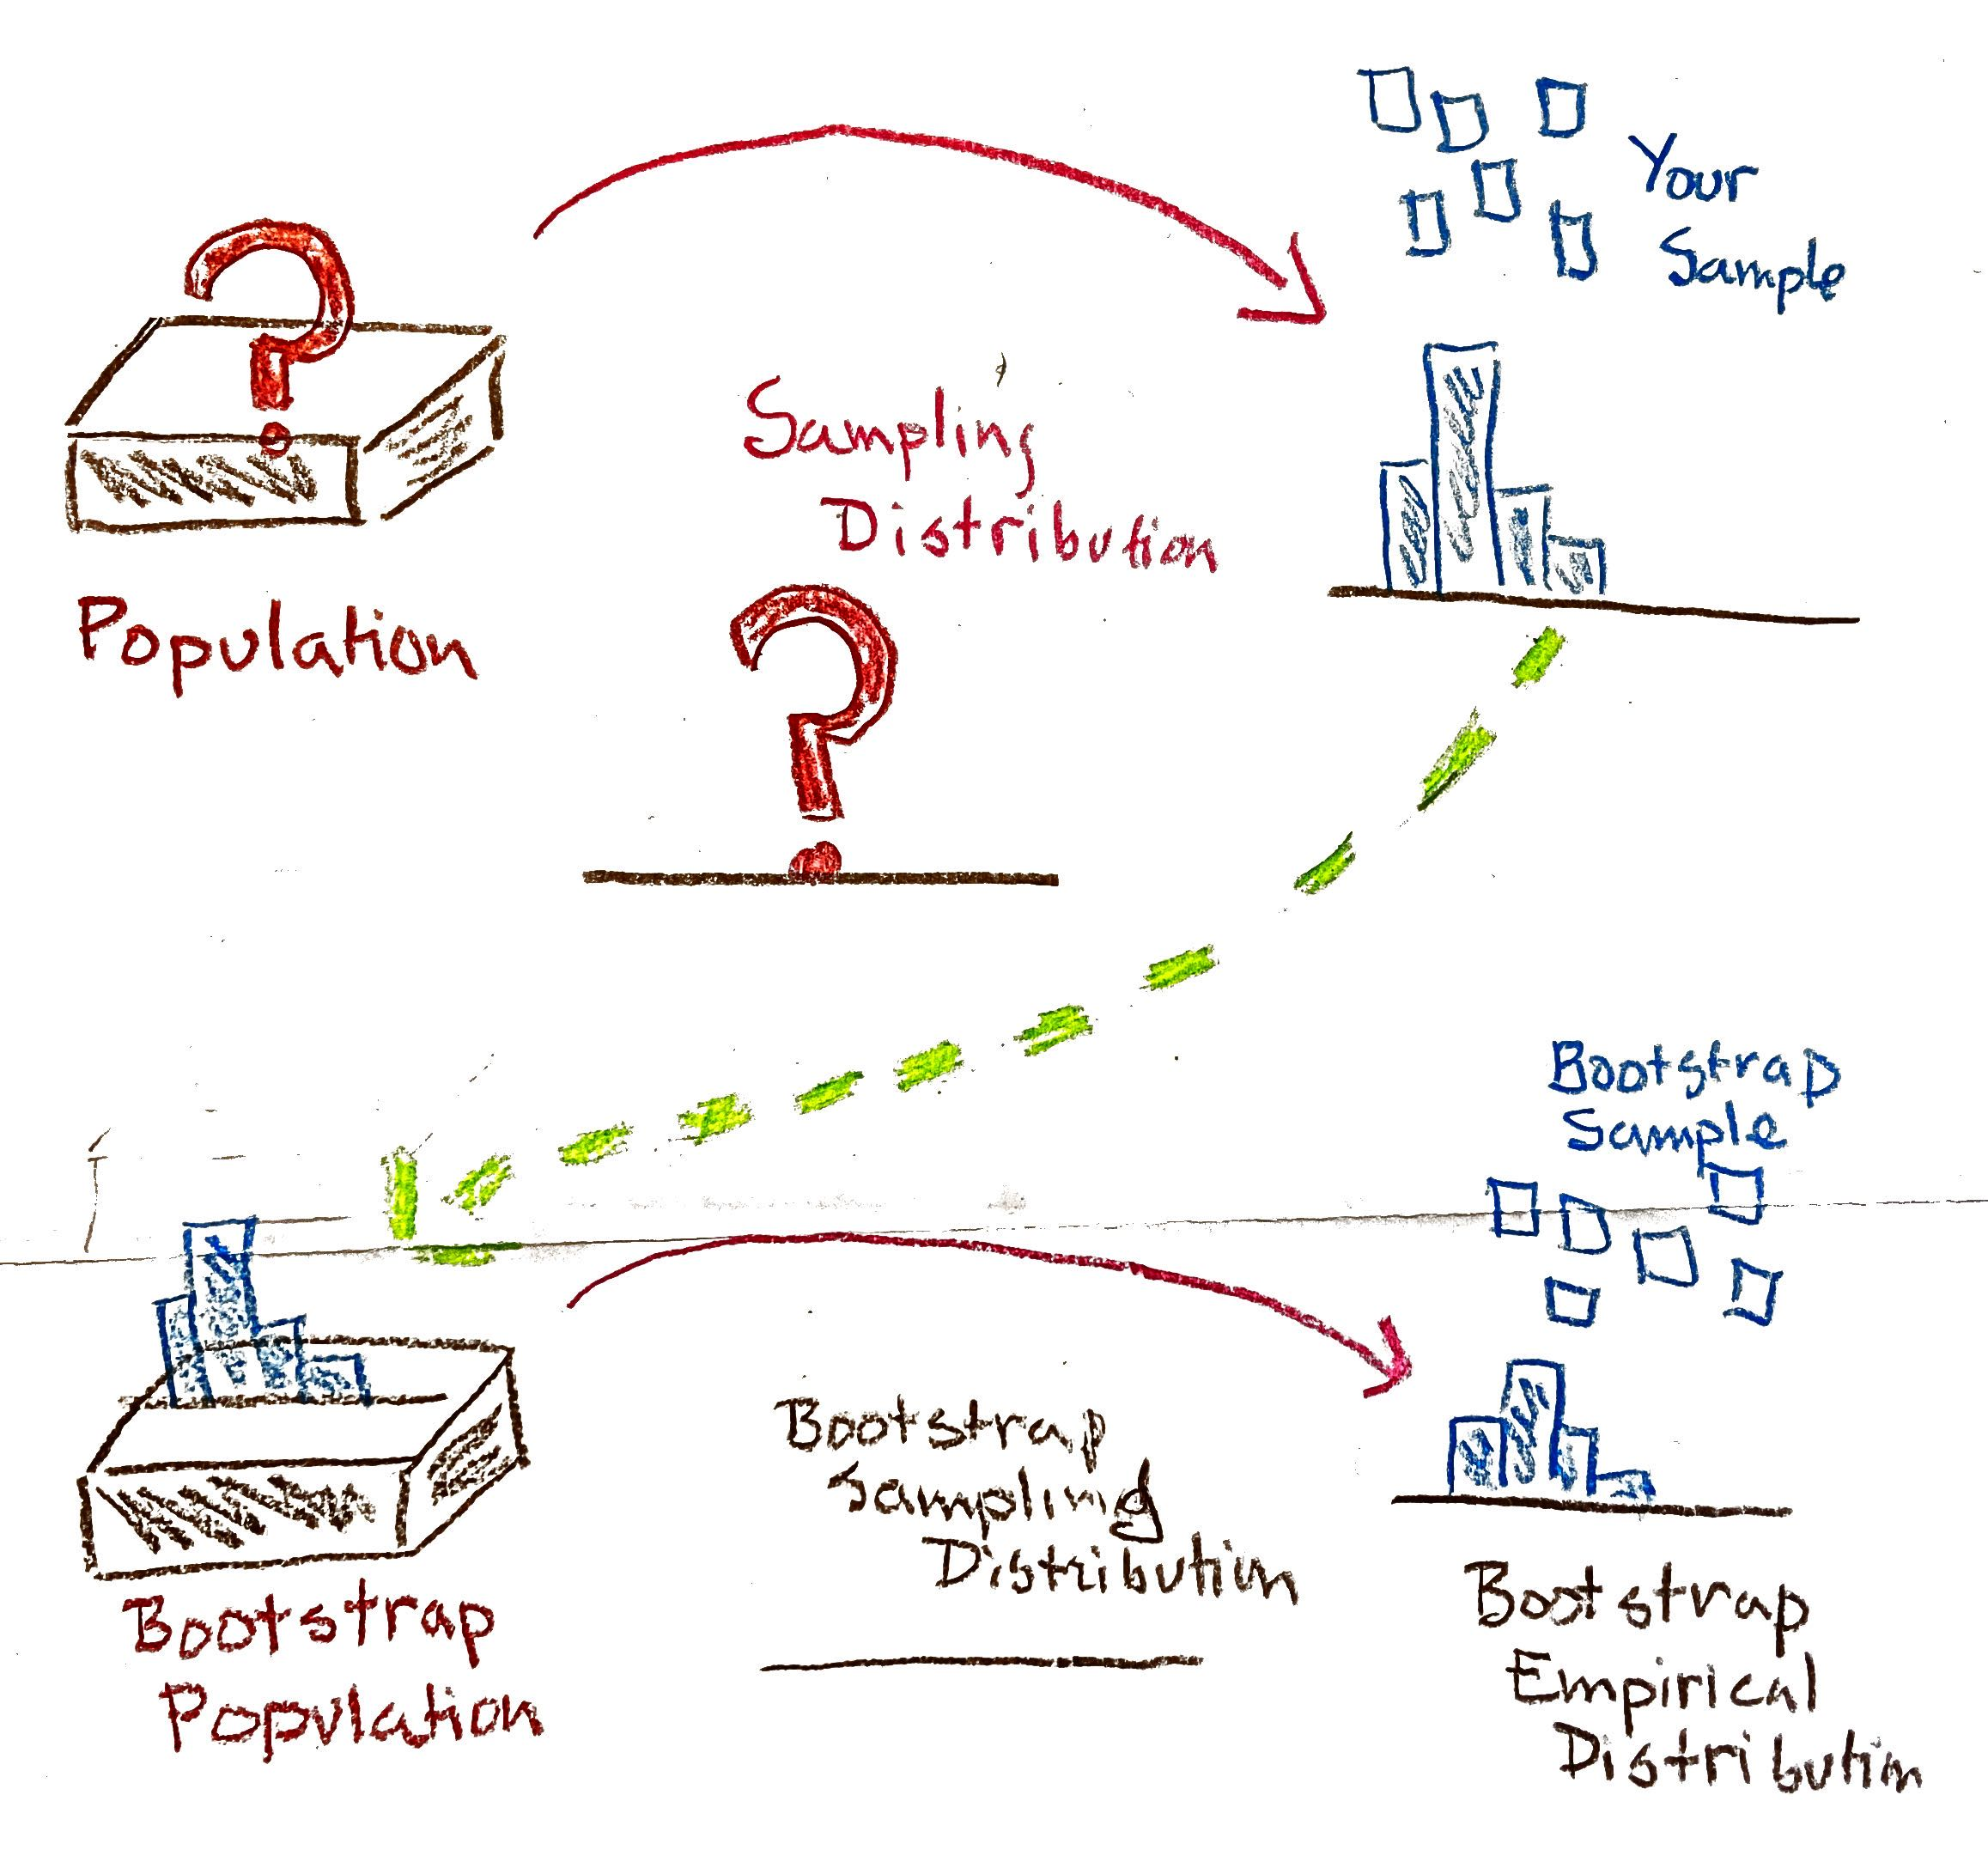

*Hình tham khảo 10.14: Mẫu thực nghiệm thay thế tổng thể trong bootstrap. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.3, hình nhúng trong học liệu gốc.*

Bên trái là cách ta muốn làm mà không làm được: lấy nhiều mẫu mới từ tổng thể. Bên phải là bootstrap: lấy nhiều mẫu từ mẫu đã có. Phần tổng thể chưa quan sát vẫn không được biết thêm gì.

Ô dưới vẽ lại sơ đồ ba bước của slide (trang 9). Bảng `bootstrap_steps` chứa vị trí và chữ của ba ô; `\n` trong chuỗi là xuống dòng.

In [2]:
bootstrap_steps=pd.DataFrame({'x':[0,1,2],'y':[0,0,0],
    'label':['Mẫu gốc cố định\nn quan sát','Rút n vị trí\ncó hoàn lại','Tính T*\nlặp B lần']})

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `geom_label` đặt mỗi dòng của `bootstrap_steps` thành một ô chữ có nền tại tọa độ `(x, y)`. `geom_segment` với `inherit_aes=False` vẽ một đường ngang nối ba ô mà không dùng ánh xạ của lớp chữ. `coord_cartesian` cố định khung nhìn.

<!-- branch-plot-instructions: end -->

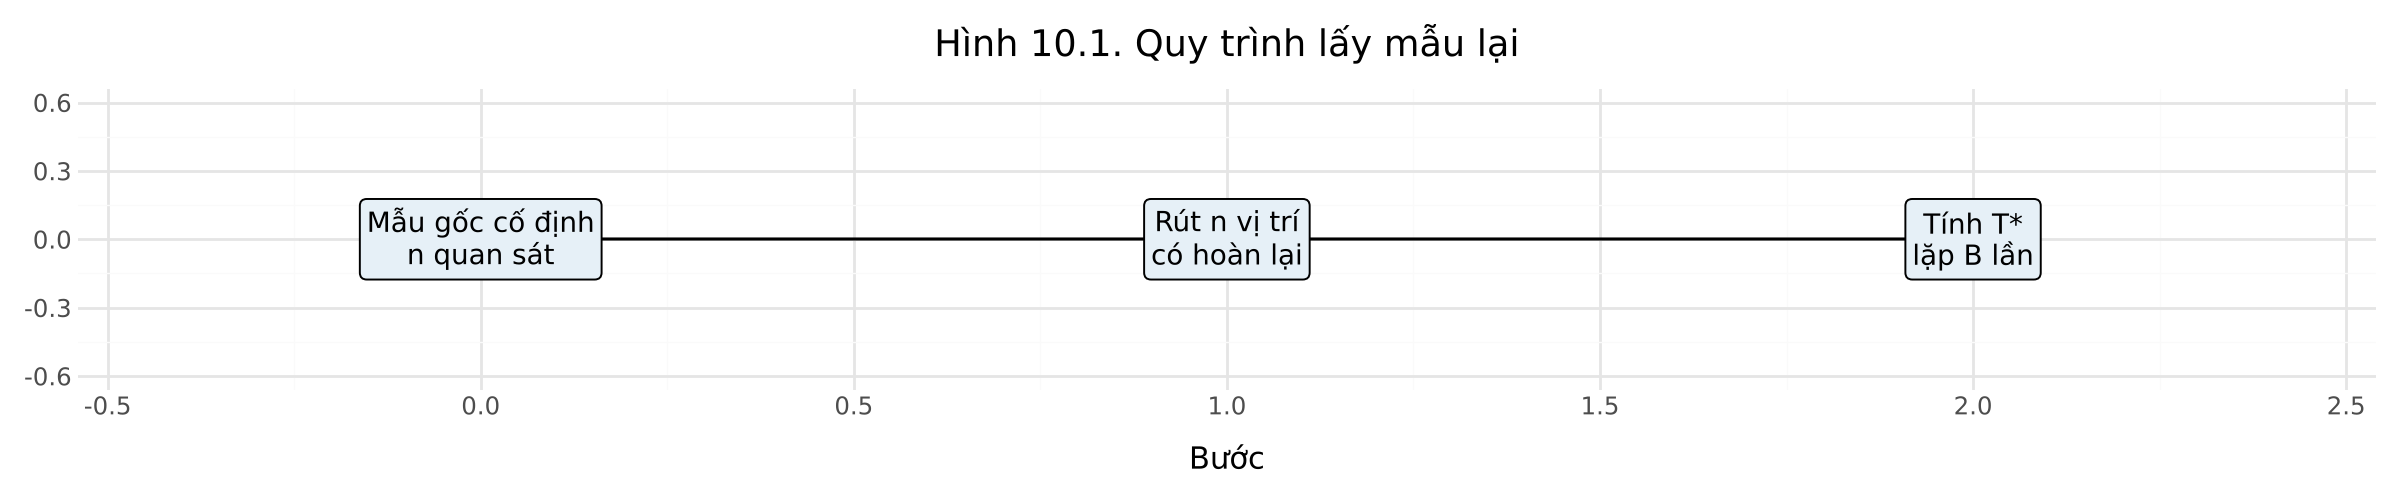

In [3]:
from plotnine import geom_label
display(ggplot(bootstrap_steps,aes('x','y',label='label'))
    +geom_segment(aes(x=0,xend=2,y=0,yend=0),inherit_aes=False)
    +geom_label(size=10,fill='#E6F0F7')
    +coord_cartesian(xlim=(-.4,2.4),ylim=(-.6,.6))
    +labs(title='Hình 10.1. Quy trình lấy mẫu lại',x='Bước',y='')
    +theme_minimal()+theme(figure_size=(12,2.5)))

Trong vòng lặp $B$ lần, chỉ bước giữa (rút lại) thay đổi. Mẫu gốc và cỡ $n$ giữ nguyên. Mỗi vòng cho đúng một giá trị $T^*$.

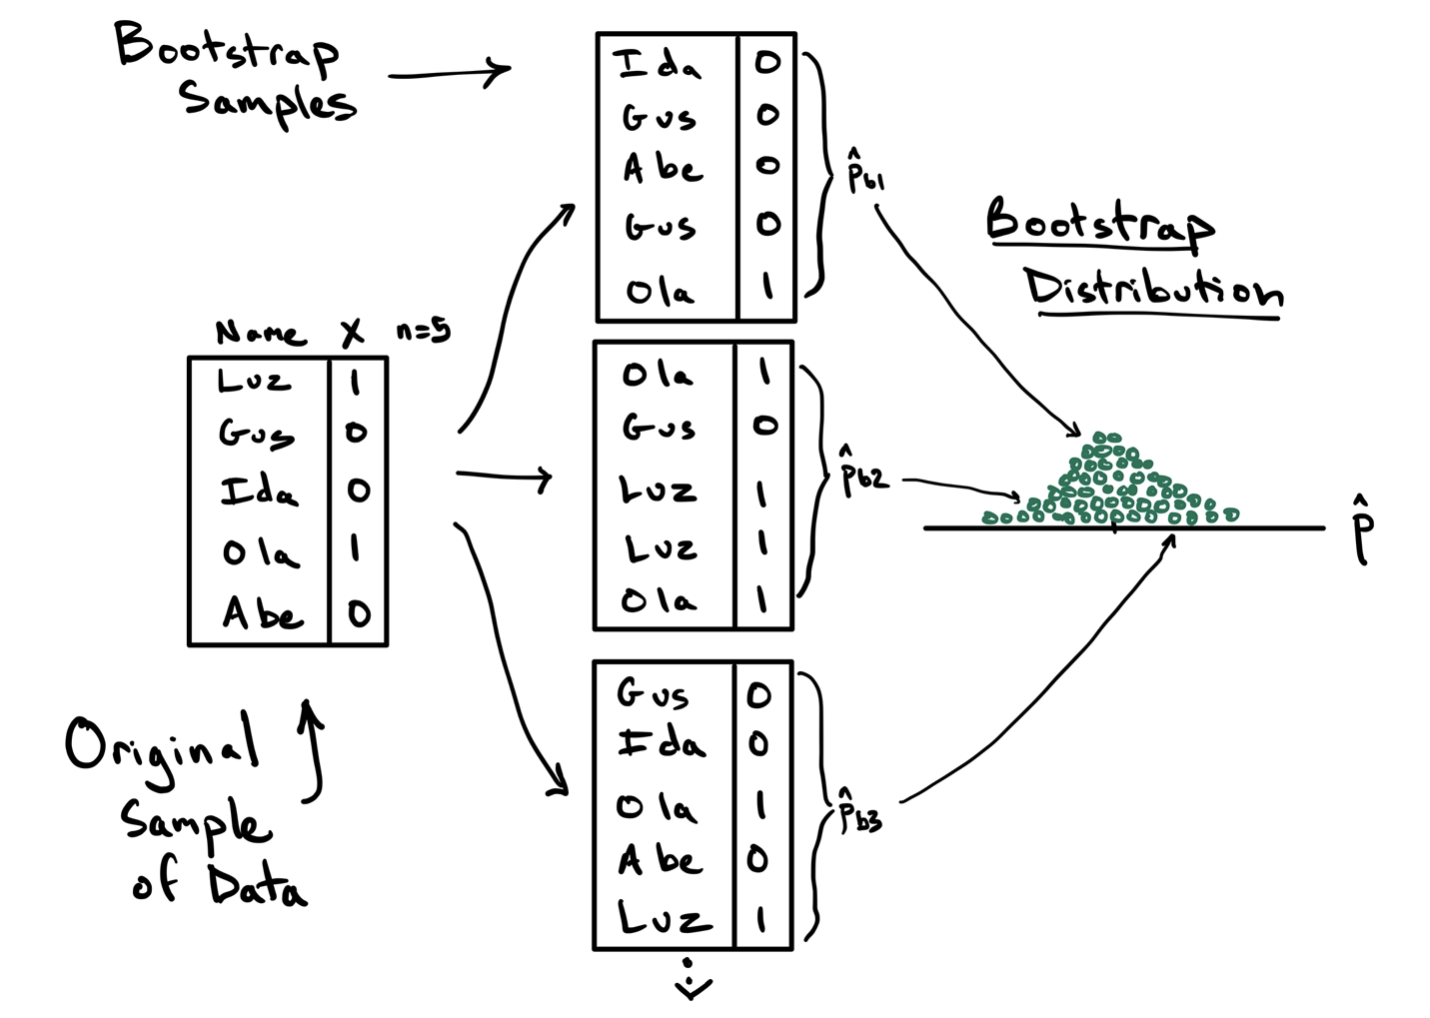

*Hình tham khảo 10.15: Lấy mẫu lại 5 chim cánh cụt. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.3, hình nhúng trong học liệu gốc.*

Mỗi cột là một mẫu bootstrap gồm 5 con, rút từ đúng 5 con của mẫu gốc. Có cột lặp cùng một con hai lần và thiếu con khác. Không có con chim mới nào xuất hiện.

### Bài toán — bootstrap bằng tay

Mẫu gồm 5 chim cánh cụt; đặt $X=1$ nếu chim mang vòng nhận dạng màu xanh, $X=0$ nếu không. Giá trị theo vị trí 1–5 là $(1,0,0,1,0)$. (1) Tính tỉ lệ mẫu $\hat p$. (2) Rút lại các vị trí $(1,1,3,4,5)$ và $(2,2,3,3,5)$; tính hai giá trị $\hat p^*$. (3) Hai mẫu này có phải được lấy mới từ tổng thể không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Mẫu gốc có hai giá trị 1: $\hat p=2/5=0{,}4$.

*Câu 2.* Thay mỗi vị trí bằng giá trị ở vị trí đó.

| Vị trí rút | Giá trị | $\hat p^*$ |
|---|---|---|
| 1, 1, 3, 4, 5 | 1, 1, 0, 1, 0 | $3/5=0{,}6$ |
| 2, 2, 3, 3, 5 | 0, 0, 0, 0, 0 | $0/5=0$ |

*Câu 3.* Không. Cả hai được tạo từ 5 quan sát ban đầu; chúng không cho thêm thông tin gì về những chim ngoài mẫu. Mẫu thứ hai cho $\hat p^*=0$ chỉ vì nó rút lặp các con không có vòng.

</details>

### Phân phối bootstrap của một tỉ lệ

Với dữ liệu 0/1, không cần mô phỏng mới biết phân phối bootstrap. Mẫu gốc có tỉ lệ $\hat p$. Mỗi lần rút có hoàn lại chọn một vị trí ngẫu nhiên, nên ra giá trị 1 với xác suất đúng bằng $\hat p$:
$$X^*_i\mid x\sim\operatorname{Bernoulli}(\hat p),\qquad K^*=\sum_{i=1}^nX^*_i.$$
Ký hiệu "$\mid x$" đọc là "khi đã biết mẫu gốc $x$". Các lần rút độc lập, nên
$$K^*\mid x\sim\operatorname{Binomial}(n,\hat p),\qquad \hat p^*=K^*/n,$$
$$E^*(\hat p^*)=\hat p,\qquad \mathrm{Var}^*(\hat p^*)=\frac{\hat p(1-\hat p)}{n},\qquad SE^*(\hat p^*)=\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

Đọc là: phân phối bootstrap có tâm ở tỉ lệ **đã quan sát** và có độ rộng giống công thức SE của Tuần 09 khi thay $p$ bằng $\hat p$. Đây là phân phối **có điều kiện trên mẫu**, không phải phân phối thật của tổng thể.

### Luyện tập cơ bản — xác suất trong mẫu bootstrap

Một nhóm kỹ thuật đo 4 cảm biến nhiệt khác nhau theo cùng quy trình. Đặt $X=1$ nếu cảm biến sai lệch không quá 0,5°C so với nhiệt kế tham chiếu, 0 nếu không. Mẫu quan sát là $(1,1,0,0)$. Lấy mẫu lại có hoàn lại cỡ $n=4$; gọi $K^*$ là số giá trị 1 trong mẫu bootstrap. (1) Tính $\hat p$ và xác định phân phối của $K^*$. (2) Tính $P^*(K^*=0)$ và $P^*(K^*\ge3)$. (3) Tính $SE^*(\hat p^*)$.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $\hat p=2/4=0{,}5$, nên $K^*\sim\operatorname{Binomial}(4;\ 0{,}5)$.

*Câu 2.* Mỗi trong $2^4=16$ dãy rút có xác suất $1/16$.
$$P^*(K^*=0)=\Big(\frac12\Big)^4=\frac1{16}=0{,}0625,\qquad P^*(K^*\ge3)=\frac{\binom43+\binom44}{16}=\frac{4+1}{16}=\frac5{16}=0{,}3125.$$

*Câu 3.* $SE^*(\hat p^*)=\sqrt{0{,}5\times0{,}5/4}=\sqrt{0{,}0625}=0{,}25$.

Mọi xác suất ở đây tính theo cơ chế lấy mẫu lại, với mẫu $(1,1,0,0)$ cố định. Chúng không phải xác suất về cả lô cảm biến.

</details>

Ô dưới kiểm tra hai bài trên. `original[np.array(positions)-1]` lấy giá trị tại các vị trí đã cho; trừ 1 vì Python đánh chỉ số từ 0. `stats.binom.sf(2, 4, .5)` là $P(K>2)=P(K\ge3)$: hàm `sf` (survival function) cho xác suất **lớn hơn hẳn** giá trị đưa vào.

In [4]:
original = np.array([1,0,0,1,0])
for positions in [[1,1,3,4,5],[2,2,3,3,5]]:
    resample = original[np.array(positions)-1]
    print(positions, resample, 'tỉ lệ =',resample.mean())
print('4 cảm biến:',stats.binom.pmf(0,4,.5),stats.binom.sf(2,4,.5),np.sqrt(.5*.5/4))
assert np.isclose(stats.binom.sf(2,4,.5),5/16)

[1, 1, 3, 4, 5] [1 1 0 1 0] tỉ lệ = 0.6
[2, 2, 3, 3, 5] [0 0 0 0 0] tỉ lệ = 0.0
4 cảm biến: 0.06250000000000001 0.3125 0.25


Hai mẫu bootstrap đều có đủ 5 lần rút, nhưng không có đủ 5 con chim khác nhau. Đó chính là điều làm $\hat p^*$ thay đổi giữa các lần.

<a id="muc-2"></a>

## 2. Từ phân phối bootstrap đến sai số chuẩn và khoảng phân vị

### Dữ liệu của cả buổi

Một nhóm kỹ thuật lấy ngẫu nhiên **100 linh kiện khác nhau** từ một lô đủ lớn; giả sử các phép đo độc lập. Linh kiện **đạt** nếu tiêu thụ không quá 2,0 Wh trong một chu trình chuẩn. Đặt $X_i=1$ nếu linh kiện $i$ đạt, 0 nếu không.

- Quan sát: 62 đạt, 38 không đạt; $\hat p=0{,}62$.
- Tham số: $p$ = tỉ lệ đạt trong tổng thể linh kiện mục tiêu.
- Đơn vị: **một linh kiện**.

Đây là số liệu giả định của slide.

### Sai số chuẩn bootstrap

Có $B$ giá trị $T^*_1,\ldots, T^*_B$ với trung bình $\bar T^*$. Sai số chuẩn bootstrap là **độ lệch chuẩn của các giá trị ấy**:
$$\widehat{SE}_{boot}(T)=\sqrt{\frac1{B-1}\sum_{b=1}^B\big(T^*_b-\bar T^*\big)^2}.$$
Đọc là: tính độ lệch chuẩn của $B$ con số $T^*$, đúng như tính độ lệch chuẩn của một cột dữ liệu. Không nhầm với độ lệch chuẩn của 100 quan sát 0/1 ban đầu.

Với tỉ lệ, công thức ở mục 1 cho $SE^*=\sqrt{0{,}62\times0{,}38/100}\approx0{,}04854$. Mô phỏng chỉ để kiểm tra, và để dùng cho những thống kê không có công thức.

### Khoảng tin cậy theo phân vị

Khoảng 95% theo phân vị lấy 95% phần giữa của phân phối bootstrap:
$$CI_{95\%,\, perc}=\big[q^*_{0{,}025},\ q^*_{0{,}975}\big].$$
Bỏ 2,5% giá trị $T^*$ nhỏ nhất và 2,5% lớn nhất; hai giá trị ở chỗ cắt là hai đầu mút.

Sau khi tính, khoảng là cố định; mức 95% vẫn nói về **quy trình**, như ở Tuần 09. Khoảng phân vị chỉ bao phủ đúng khoảng 95% khi phân phối bootstrap có hình dạng giống phân phối mẫu thật; với mẫu nhỏ hoặc thống kê kỳ quặc, độ bao phủ có thể lệch.

**$B$ và $n$ là hai thứ khác nhau.** $B$ là số lần lấy mẫu lại: tăng $B$ chỉ làm kết quả mô phỏng ổn định hơn. $n$ là cỡ mẫu thật: chỉ tăng $n$ (thu thêm dữ liệu) mới làm SE nhỏ đi.

Ô dưới chạy bootstrap $B=20\,000$ lần. `r_boot.choice(components, size=(B, 100), replace=True)` tạo một bảng $B$ hàng, mỗi hàng là một mẫu bootstrap 100 phần tử; `.mean(axis=1)` lấy trung bình theo từng hàng, cho $B$ giá trị $\hat p^*$. `np.quantile(p_boot, [.025, .975])` cắt 2,5% hai đầu.

**Bạn đoán trước:** SE mô phỏng gần 0,0485 không? Khoảng có đối xứng quanh 0,62 không?

In [5]:
components = np.r_[np.ones(62),np.zeros(38)]
B = 20_000  # Thử đổi: 500, 5000, 20000
r_boot = np.random.default_rng(20261010)  # seed gốc của slide để đối chiếu
p_boot = r_boot.choice(components, size=(B,len(components)), replace=True).mean(axis=1)
ci_boot = np.quantile(p_boot,[.025,.975])
print('p̂:',components.mean(),'SE mô phỏng:',p_boot.std(ddof=1))
print('SE có điều kiện theo công thức:',np.sqrt(.62*.38/100))
print('Khoảng phân vị:',ci_boot)
boot_table = pd.DataFrame({'proportion':p_boot})

p̂: 0.62 SE mô phỏng: 0.04856669904330331
SE có điều kiện theo công thức: 0.048538644398046386
Khoảng phân vị: [0.52    0.71025]


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(boot_table, aes(...))` lấy bảng `boot_table`; trong `aes`, trục ngang là cột `proportion`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `0.62`.

**Đọc hình.** Mỗi cột đếm số mẫu bootstrap cho cùng một tỉ lệ (tỉ lệ chỉ nhận các giá trị $k/100$, nên histogram có răng cưa). Đường đứt đoạn là $\hat p=0{,}62$. Ước lượng bằng mắt hai điểm cắt bỏ 2,5% mỗi đuôi, rồi so với khoảng in ra.

<!-- branch-plot-instructions: end -->

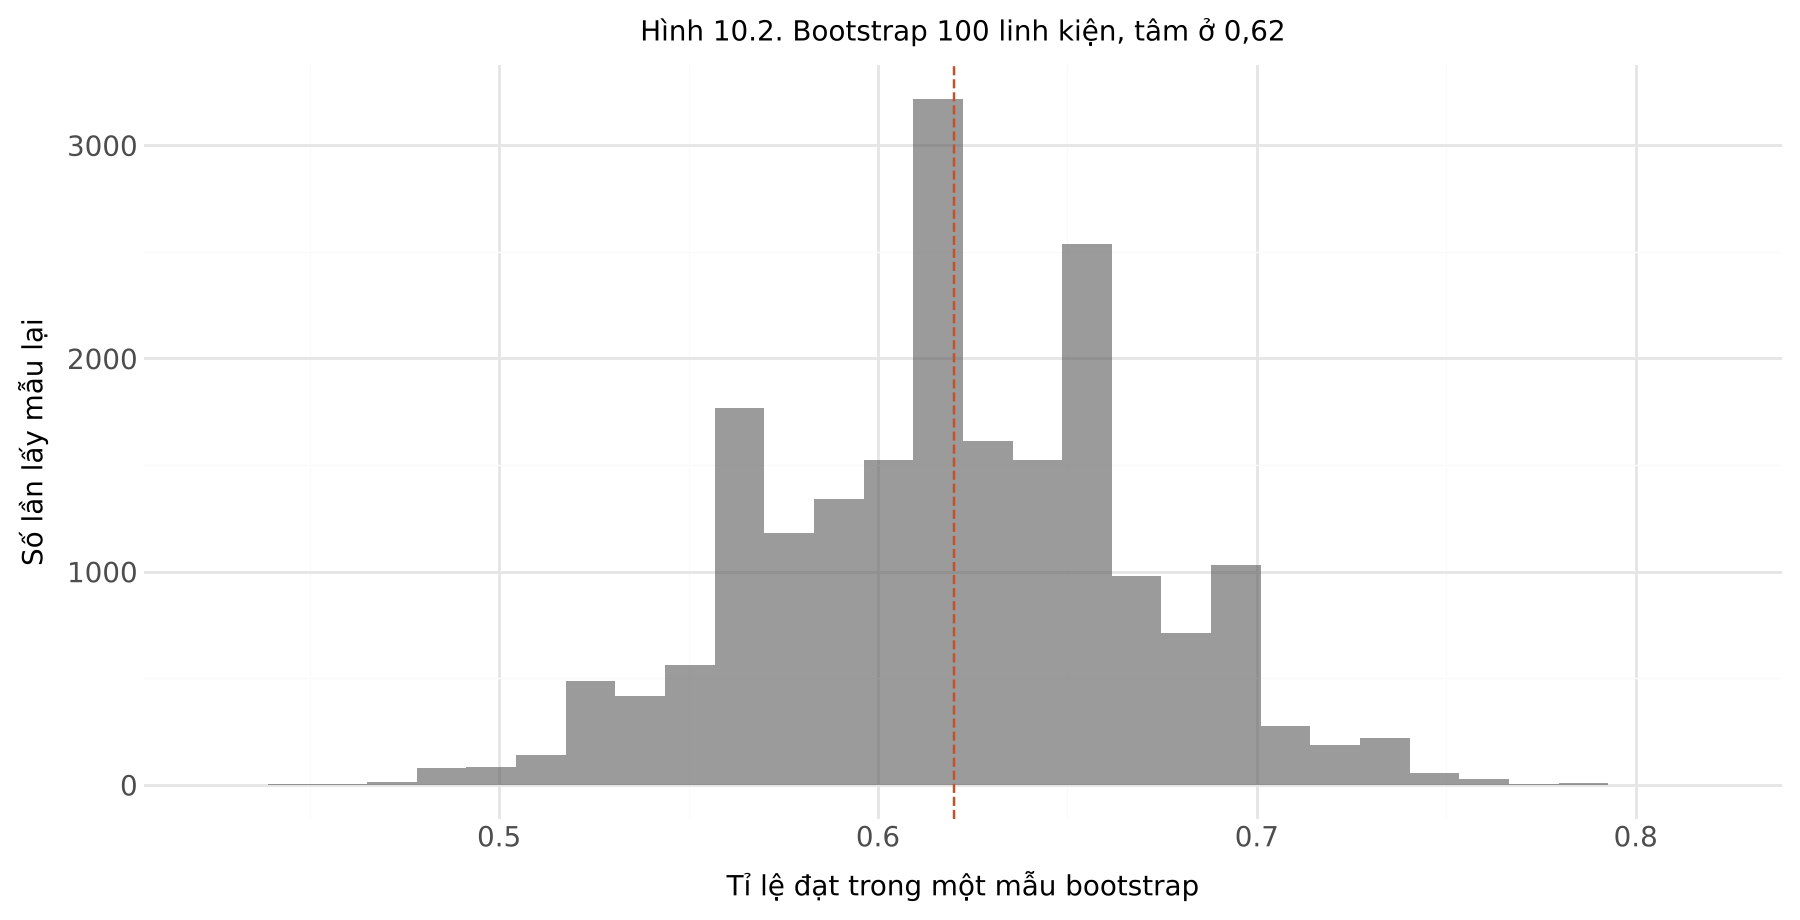

In [6]:
p = (ggplot(boot_table, aes(x='proportion'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=0.62, linetype='dashed', color='#C4512A')
     + labs(title='Hình 10.2. Bootstrap 100 linh kiện, tâm ở 0,62', x='Tỉ lệ đạt trong một mẫu bootstrap', y='Số lần lấy mẫu lại')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** SE bootstrap $\approx0{,}0486$, khớp công thức 0,04854. Khoảng phân vị $[0{,}52;\ 0{,}71]$, gần đối xứng quanh 0,62.

**Diễn giải.** Theo quy trình lấy mẫu và mô hình bootstrap đã giả định, $[0{,}52;\ 0{,}71]$ là khoảng ước lượng cho tỉ lệ đạt $p$ của tổng thể, mức tin cậy danh nghĩa 95%.

- Không nói: "95% linh kiện có giá trị từ 0,52 đến 0,71". Mỗi linh kiện chỉ là 0 hoặc 1.
- Không mở rộng cho mọi lô nếu mẫu bị chọn lệch hoặc các phép đo phụ thuộc nhau.

**Thử đổi.** Đặt `B = 500` rồi chạy lại: SE và hai đầu mút xê dịch ở chữ số thứ ba. Đặt lại `B = 20_000`: chúng ổn định. Cả hai lần, độ rộng khoảng vẫn quanh 0,19, vì nó do $n=100$ quyết định.

### Bài toán vận dụng — bootstrap hệ số góc hồi quy

Một nhóm kỹ thuật đo 4 thiết bị khác nhau, chọn ngẫu nhiên và độc lập: thời gian vận hành $x$ (giờ) là 1, 2, 3, 4; độ lệch nhiệt độ $y$ (°C) là 2, 3, 5, 4. (1) Tính hệ số góc bình phương tối thiểu $b_1=\sum(x_i-\bar x)(y_i-\bar y)\big/\sum(x_i-\bar x)^2$. (2) Lấy mẫu lại **cả cặp** $(x, y)$ theo các vị trí $(1,1,3,4)$, tính $b_1^*$.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $\bar x=2{,}5$, $\bar y=3{,}5$.

| $i$ | $x_i-\bar x$ | $y_i-\bar y$ | tích | $(x_i-\bar x)^2$ |
|---|---|---|---|---|
| 1 | −1,5 | −1,5 | 2,25 | 2,25 |
| 2 | −0,5 | −0,5 | 0,25 | 0,25 |
| 3 | 0,5 | 1,5 | 0,75 | 0,25 |
| 4 | 1,5 | 0,5 | 0,75 | 2,25 |
| Tổng | | | 4 | 5 |

$b_1=4/5=0{,}8$ °C/giờ.

*Câu 2.* Các cặp được rút: $(1,2),(1,2),(3,5),(4,4)$. $\bar x^*=2{,}25$, $\bar y^*=3{,}25$.

| cặp | $x-\bar x^*$ | $y-\bar y^*$ | tích | bình phương |
|---|---|---|---|---|
| (1, 2) | −1,25 | −1,25 | 1,5625 | 1,5625 |
| (1, 2) | −1,25 | −1,25 | 1,5625 | 1,5625 |
| (3, 5) | 0,75 | 1,75 | 1,3125 | 0,5625 |
| (4, 4) | 1,75 | 0,75 | 1,3125 | 3,0625 |
| Tổng | | | 5,75 | 6,75 |

$b_1^*=5{,}75/6{,}75=23/27\approx0{,}852$.

*Vì sao rút cả cặp?* Hệ số góc đo **quan hệ** giữa $x$ và $y$ của cùng một thiết bị. Rút cột $x$ và cột $y$ riêng sẽ ghép nhầm $x$ của thiết bị này với $y$ của thiết bị khác, làm mất chính quan hệ cần đo.

*Lưu ý.* Với chỉ 4 thiết bị, có những mẫu bootstrap rút cùng một $x$ cả 4 lần (ví dụ vị trí $(2,2,2,2)$); khi đó mẫu số bằng 0 và hệ số góc không xác định. Kết quả bootstrap với mẫu nhỏ như vậy không đáng tin.

</details>

In [7]:
x = np.array([1.,2.,3.,4.]); y = np.array([2.,3.,5.,4.])
def slope(x,y):
    return ((x-x.mean())*(y-y.mean())).sum()/((x-x.mean())**2).sum()
idx = np.array([0,0,2,3])
print('Gốc:',slope(x,y),'mẫu lại:',slope(x[idx],y[idx]))
assert np.isclose(slope(x[idx],y[idx]),23/27)

Gốc: 0.8 mẫu lại: 0.8518518518518519


### Bootstrap không sửa được gì

| Tình huống | Vì sao bootstrap không giúp |
|---|---|
| Mẫu bị chọn lệch | Bootstrap không thể tạo ra nhóm chưa từng được quan sát. |
| Dữ liệu phụ thuộc (theo thiết bị, cụm, thời gian) | Rút từng dòng độc lập phá vỡ cấu trúc phụ thuộc, nên SE bị đánh giá thấp. Phải rút theo cụm hoặc theo khối. |
| Mẫu rất nhỏ | Phân phối thực nghiệm quá nghèo; khoảng phân vị có thể sai nặng. |
| Mẫu toàn một giá trị | Mọi mẫu bootstrap giống hệt nhau; SE bằng 0 dù tổng thể có thể rất đa dạng. |

Tăng $B$ chỉ giảm sai số do mô phỏng hữu hạn, không chạm tới bốn vấn đề trên. Bài toán thử thách A ở mục 6 là một ví dụ cụ thể.

<a id="muc-3"></a>

## 3. Kiểm định đặt ra một thế giới giả định khác

### Một bộ dữ liệu, hai câu hỏi

Cùng 62/100 linh kiện đạt:

| | Bootstrap (mục 1–2) | Kiểm định (mục này) |
|---|---|---|
| Câu hỏi | $p$ khoảng bao nhiêu, bất định đến đâu? | Nếu $p=0{,}5$ thì 62/100 có bất thường không? |
| Mốc tham chiếu | mẫu đã quan sát, $\hat p=0{,}62$ | mô hình giả định, $p_0=0{,}50$ |
| Cách dựng phân phối | lấy mẫu lại có hoàn lại từ mẫu | tính từ mô hình $H_0$ hoặc từ các phép gán hợp lệ |
| Kết quả | SE, khoảng tin cậy | giá trị p |

Kiểm định trả lời câu hỏi qua sáu bước.

### Bước 1 — Câu hỏi, đơn vị, dữ liệu

Câu hỏi: tỉ lệ đạt chuẩn của linh kiện trong tổng thể mục tiêu có **lớn hơn 50%** không? Đơn vị là một linh kiện; $n=100$, $k_{obs}=62$.

### Bước 2 — Giả thuyết không và giả thuyết đối

- **Giả thuyết không** $H_0$: một phát biểu về tham số (hay về cơ chế tạo dữ liệu), cụ thể đến mức dựng được phân phối của thống kê. Ở đây $H_0: p=0{,}50$.
- **Giả thuyết đối** $H_A$: điều ta muốn tìm bằng chứng, theo hướng của câu hỏi. Ở đây $H_A: p>0{,}50$.

Phải viết $H_0$ và **hướng** của $H_A$ **trước khi** xem dữ liệu.

### Bước 3 — Thống kê kiểm định

Thống kê $T$ là một hàm của dữ liệu, đo mức dữ liệu "không hợp" với $H_0$. Ở đây dùng số linh kiện đạt $T=K=\sum X_i$, giá trị quan sát $t_{obs}=62$. Dùng $\hat p=K/100$ cũng được, vì hai cái tăng giảm cùng nhau. Theo $H_A: p>0{,}5$, **$K$ càng lớn** càng là bằng chứng chống $H_0$.

### Bước 4 — Phân phối dưới $H_0$

Câu hỏi then chốt: nếu $H_0$ đúng, $K$ dao động thế nào? Nếu 100 linh kiện là các phép thử Bernoulli độc lập với xác suất $p_0=0{,}5$, thì
$$K\mid H_0\sim\operatorname{Binomial}(100;\ 0{,}5),\qquad P_{H_0}(K=k)=\binom{100}k(0{,}5)^{100},$$
với $E_{H_0}(K)=50$ và $\mathrm{SD}_{H_0}(K)=\sqrt{100\times0{,}5\times0{,}5}=5$. Đây là phân phối **chính xác**, tính thẳng được, không cần mô phỏng. Dưới $H_0$, các giá trị quanh 50 là phổ biến; 62 cách tâm 12, tức 2,4 độ lệch chuẩn, nằm ở đuôi phải.

### Bước 5 — Giá trị p

**Giá trị p** là xác suất, **tính với giả định $H_0$ và mô hình đều đúng**, thu được thống kê **ít nhất cực đoan như** giá trị đã quan sát, theo hướng của $H_A$:
$$\text{giá trị p}=P_{H_0}(K\ge62)=\sum_{k=62}^{100}\binom{100}k(0{,}5)^{100}\approx0{,}0104894.$$
Ba điểm cần nhớ:

- Cộng **cả đuôi** $K\ge62$, không chỉ $P(K=62)$. Một giá trị cụ thể của biến rời rạc nhiều khả năng luôn có xác suất nhỏ; cái ta hỏi là "62 **hoặc tệ hơn nữa** đối với $H_0$".
- "Cực đoan" do $H_A$ quyết định: với $H_A: p>0{,}5$ là đuôi phải.
- Giá trị p tính **trong thế giới $H_0$**. Nó không phải xác suất $H_0$ đúng.

### Bước 6 — Quyết định và diễn giải

Chọn trước mức ý nghĩa $\alpha$ (ở đây $\alpha=0{,}05$). Nếu giá trị p $\le\alpha$, bác bỏ $H_0$.

Ở đây $0{,}0105<0{,}05$, nên **bác bỏ $H_0: p=0{,}50$**. Kết luận: dữ liệu cho bằng chứng thống kê theo hướng tỉ lệ đạt chuẩn trong tổng thể mục tiêu lớn hơn 50%, nếu giả định lấy mẫu và mô hình Bernoulli độc lập phù hợp. Không được nói "$H_0$ đúng với xác suất 1,05%". Mức ý nghĩa và các loại sai lầm sẽ học kỹ ở Tuần 11.

Ô dưới tính giá trị p theo hai cách.

- **Chính xác:** `stats.binomtest(62, 100, .5, alternative='greater').pvalue` cộng đuôi nhị thức $P(K\ge62)$. Cùng con số này cũng có được bằng `stats.binom.sf(61, 100, .5)`; dùng 61 chứ không phải 62 vì `sf(k)` là $P(K>k)$.
- **Mô phỏng:** sinh 50.000 giá trị $K$ từ $\operatorname{Binomial}(100;\ 0{,}5)$, tức 50.000 "thí nghiệm trong thế giới $H_0$", rồi đếm tỉ lệ lần $K\ge62$. Dòng `mc_se` tính sai số chuẩn của chính ước lượng mô phỏng này, $\sqrt{p(1-p)/50\,000}$.

In [8]:
p_exact = stats.binomtest(62,100,.5,alternative='greater').pvalue
null_k = np.random.default_rng(20261011).binomial(100,.5,50_000)
p_mc = np.mean(null_k>=62)
mc_se = np.sqrt(p_exact*(1-p_exact)/len(null_k))
print('Nhị thức chính xác:',p_exact,'; mô phỏng:',p_mc,'; SE Monte Carlo:',mc_se)
k = np.arange(101)
null_pmf = pd.DataFrame({'k':k,'probability':stats.binom.pmf(k,100,.5),
                        'region':np.where(k>=62,'K ≥ 62','Phần còn lại')})

Nhị thức chính xác: 0.01048936783892586 ; mô phỏng: 0.01006 ; SE Monte Carlo: 0.0004556169663492695


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(null_pmf, aes(...))` lấy bảng `null_pmf`; trong `aes`, trục ngang là cột `k`, trục đứng là cột `probability`. `fill='region'` cho mỗi giá trị của cột `region` một màu riêng. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `62`.

**Đọc hình.** Mỗi cột là $P_{H_0}(K=k)$; cả hình là phân phối dưới $H_0$, tâm 50. Các cột tô màu khác từ 62 trở lên là vùng cực đoan. Giá trị p là **tổng chiều cao** của các cột đó.

<!-- branch-plot-instructions: end -->

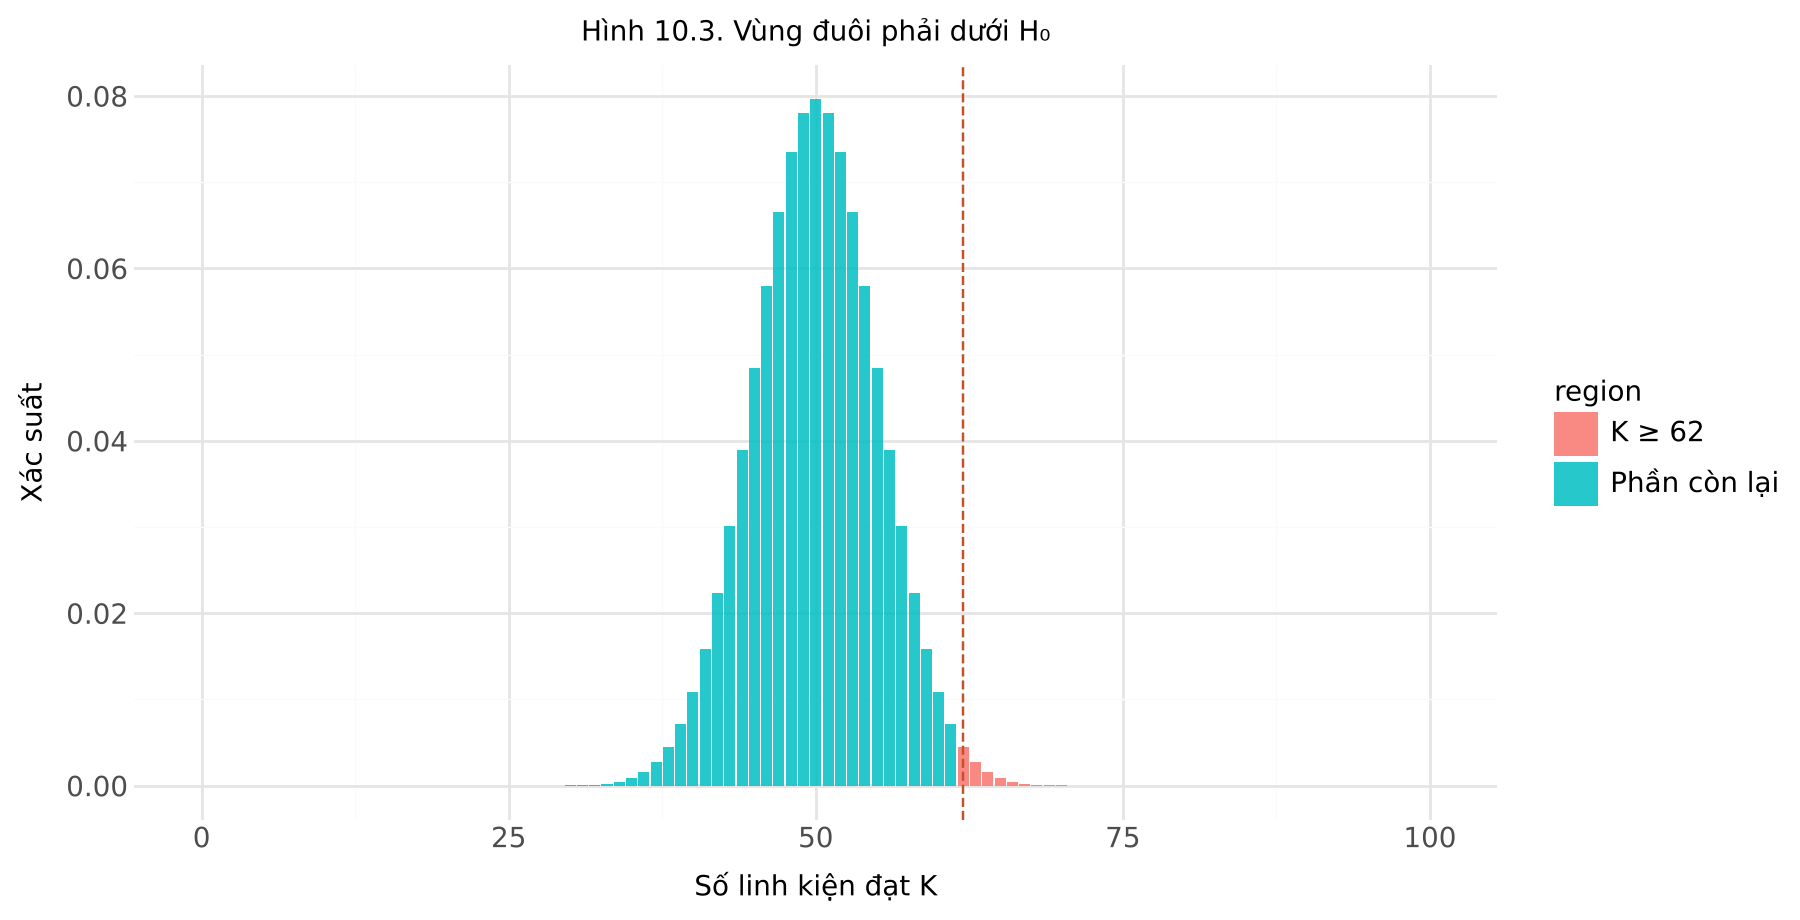

In [9]:
p = (ggplot(null_pmf, aes(x='k', y='probability', fill='region'))
     + geom_col(position='dodge', alpha=0.85)
     + geom_vline(xintercept=62, linetype='dashed', color='#C4512A')
     + labs(title='Hình 10.3. Vùng đuôi phải dưới H₀', x='Số linh kiện đạt K', y='Xác suất')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Mô phỏng cho khoảng 0,0101, nhị thức chính xác cho 0,01049. Chênh lệch khoảng 0,0004, đúng cỡ SE Monte Carlo 0,00046. Hai cách nhất quán; khi tính chính xác được, dùng kết quả chính xác.

### Xấp xỉ chuẩn cho kiểm định tỉ lệ

Dưới $H_0: p=p_0$, $\hat p$ có tâm $p_0$ và sai số chuẩn tính **theo $p_0$**:
$$SE_{H_0}(\hat p)=\sqrt{\frac{p_0(1-p_0)}n},\qquad Z=\frac{\hat p-p_0}{SE_{H_0}(\hat p)}.$$
Dùng $Z\approx\mathcal N(0,1)$ khi các quan sát độc lập và số thành công, thất bại **kỳ vọng dưới $H_0$** đủ lớn: $np_0\ge10$ và $n(1-p_0)\ge10$.

Với 100 linh kiện: $Z=(0{,}62-0{,}50)/\sqrt{0{,}25/100}=0{,}12/0{,}05=2{,}40$, $P(Z\ge2{,}40)\approx0{,}0082$. Con số này khác 0,01049 vì đã thay một phân phối rời rạc bằng một đường cong liên tục; đó là sai số xấp xỉ, không phải hai kết luận mâu thuẫn.

| Phương pháp | SE tính theo |
|---|---|
| Kiểm định $H_0: p=p_0$ | $p_0$ (tỉ lệ giả định) |
| Khoảng tin cậy xấp xỉ chuẩn (Tuần 09) | $\hat p$ |
| Bootstrap tỉ lệ | độ lệch chuẩn của các $\hat p^*$, xấp xỉ $\sqrt{\hat p(1-\hat p)/n}$ |

### Bài toán — cùng dữ liệu, hai giả thuyết đối

Giữ nguyên $n=100$, $K_{obs}=62$ và $H_0: p=0{,}5$. Nhóm A đặt $H_A: p>0{,}5$; nhóm B đặt $H_A: p\ne0{,}5$. (1) Hai nhóm cần tính những vùng đuôi nào? (2) Giá trị p khác nhau thế nào? (3) Có hợp lý không khi xem dữ liệu trước rồi mới quyết định dùng một phía?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Nhóm A: chỉ đuôi phải $K\ge62$. Nhóm B: lệch khỏi 50 theo **cả hai hướng** ít nhất 12 đơn vị, tức $K\ge62$ hoặc $K\le38$.

*Câu 2.* Một phía: $P_{H_0}(K\ge62)\approx0{,}01049$. Hai phía: vì $\operatorname{Binomial}(100;\ 0{,}5)$ đối xứng quanh 50, $P(K\le38)=P(K\ge62)$, nên giá trị p $\approx2\times0{,}01049=0{,}02098$. Dữ liệu không đổi; chỉ vùng "cực đoan" đổi theo $H_A$.

Việc gấp đôi chỉ đúng vì phân phối này đối xứng. Với phân phối không đối xứng (ví dụ $p_0=0{,}3$, hay bài Gilbert ở mục 5), phải tính thẳng hai đuôi theo định nghĩa.

*Câu 3.* Không. Nếu nhìn thấy $\hat p>0{,}5$ rồi mới chọn $H_A: p>0{,}5$, ta luôn chọn được phía có lợi; giá trị p thật của cả quy trình khi đó gần với giá trị p hai phía. Chọn hướng sau khi xem dữ liệu là **đánh giá quá mức** bằng chứng chống $H_0$.

</details>

Ô dưới tính $Z$ và các giá trị p, lập bảng so hai SE (kiểm định dùng 0,5, bootstrap dùng 0,62), và chuẩn bị dữ liệu cho hai hình: vùng hai đuôi, và hai đường chuẩn có tâm 0,50 và 0,62.

In [10]:
z_obs = (.62-.5)/np.sqrt(.5*.5/100)
print('z:',z_obs,'p chuẩn không hiệu chỉnh:',stats.norm.sf(z_obs))
print('p nhị thức một phía:',p_exact,'hai phía:',stats.binomtest(62,100,.5).pvalue)
tail_compare = pd.DataFrame({'k':k,'probability':stats.binom.pmf(k,100,.5),
                            'region':np.where((k<=38)|(k>=62),'Hai đuôi','Giữa')})
display(pd.DataFrame({'Mục đích':['Kiểm định H₀','CI/Bootstrap'],
    'Tỉ lệ dùng':[.5,.62],'SE':[np.sqrt(.5*.5/100),np.sqrt(.62*.38/100)]}))
p_grid = np.linspace(.3,.85,350)
two_models = pd.concat([pd.DataFrame({'p_hat':p_grid,'density':stats.norm.pdf(p_grid,center,se),'model':name})
    for name,center,se in [('Dưới H₀',.5,.05),('Bootstrap',.62,np.sqrt(.62*.38/100))]])

z: 2.4 p chuẩn không hiệu chỉnh: 0.008197535924596131
p nhị thức một phía: 0.01048936783892586 hai phía: 0.02097873567785172


,Mục đích,Tỉ lệ dùng,SE
0,Kiểm định H₀,0.50,0.05000
1,CI/Bootstrap,0.62,0.04854


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(tail_compare, aes(...))` lấy bảng `tail_compare`; trong `aes`, trục ngang là cột `k`, trục đứng là cột `probability`. `fill='region'` cho mỗi giá trị của cột `region` một màu riêng. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau.

**Đọc hình.** Hai vùng tô màu ở hai đầu, $K\le38$ và $K\ge62$, có cùng diện tích vì phân phối đối xứng quanh 50. Giá trị p hai phía là tổng của cả hai vùng.

<!-- branch-plot-instructions: end -->

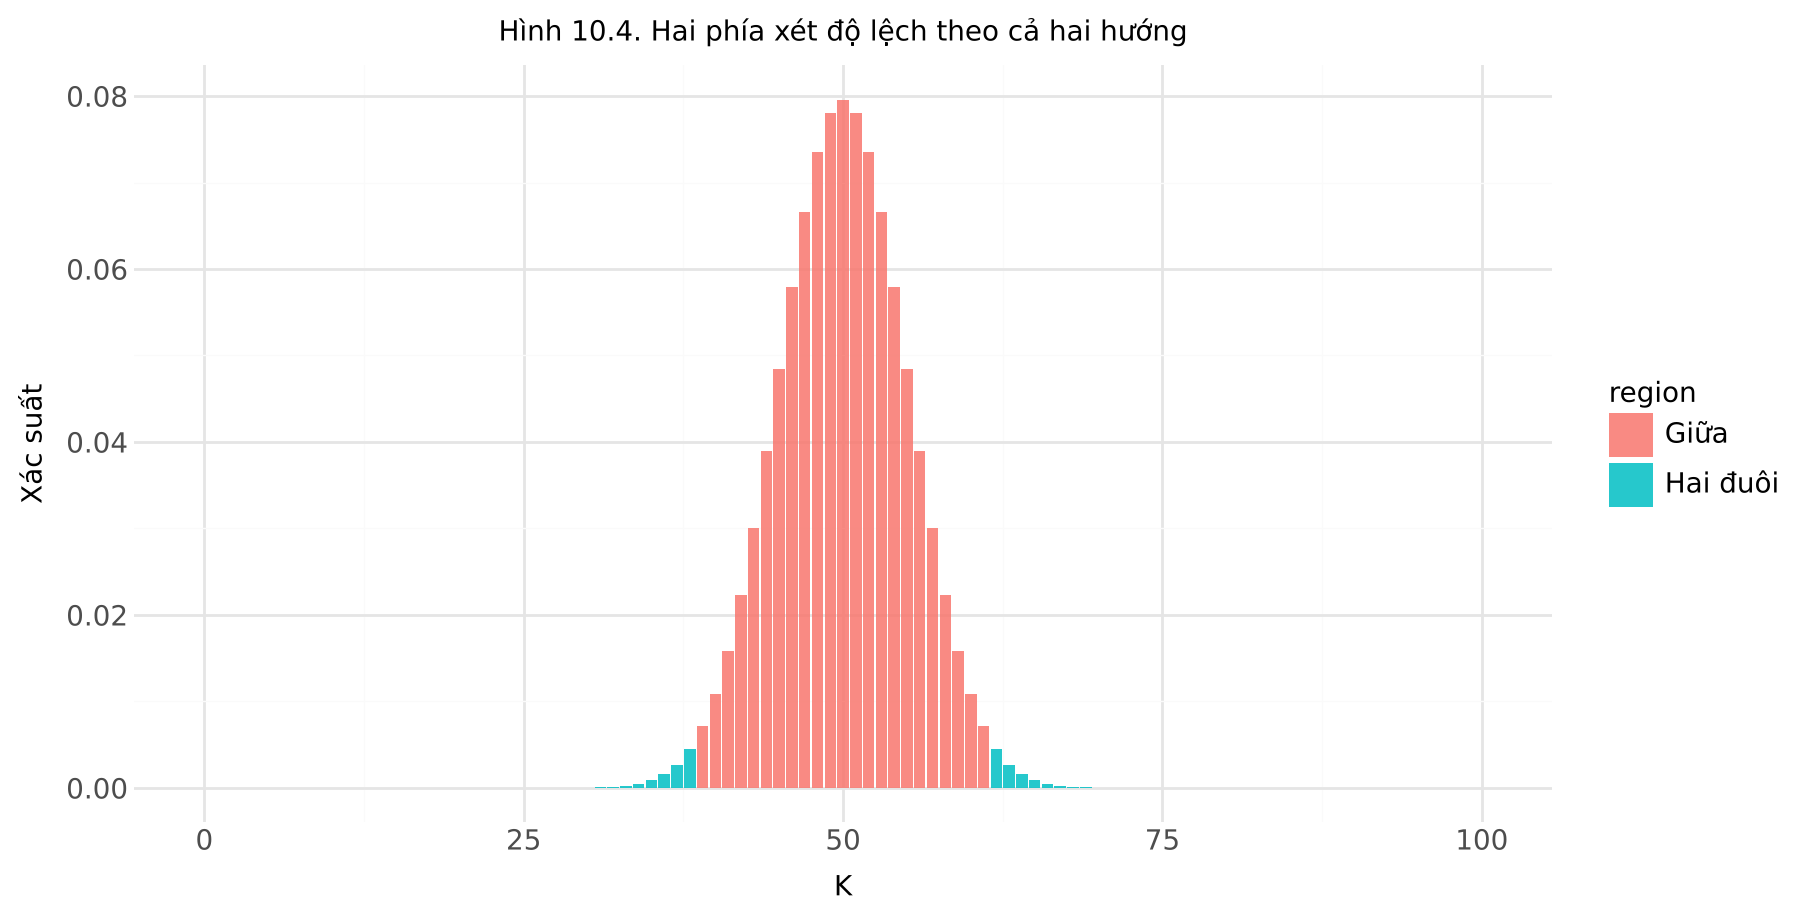

In [11]:
p = (ggplot(tail_compare, aes(x='k', y='probability', fill='region'))
     + geom_col(position='dodge', alpha=0.85)
     + labs(title='Hình 10.4. Hai phía xét độ lệch theo cả hai hướng', x='K', y='Xác suất')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Hình dưới vẽ hai đường chuẩn chỉ để so **tâm** và **độ rộng** của hai phân phối dùng cùng dữ liệu. Các xác suất đuôi của bài vẫn lấy từ nhị thức chính xác.

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(two_models, aes(...))` lấy bảng `two_models`; trong `aes`, trục ngang là cột `p_hat`, trục đứng là cột `density`. `color='model'` cho mỗi giá trị của cột `model` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang.

**Đọc hình.** Đường “Dưới H₀” có tâm 0,50: dùng để hỏi 0,62 có hiếm không. Đường “Bootstrap” có tâm 0,62: dùng để hỏi $p$ có thể nằm đâu. Hai đường gần như cùng độ rộng (SE 0,050 và 0,049) nhưng lệch tâm 0,12. Lấy đuôi của đường bootstrap làm giá trị p là trả lời nhầm câu hỏi.

<!-- branch-plot-instructions: end -->

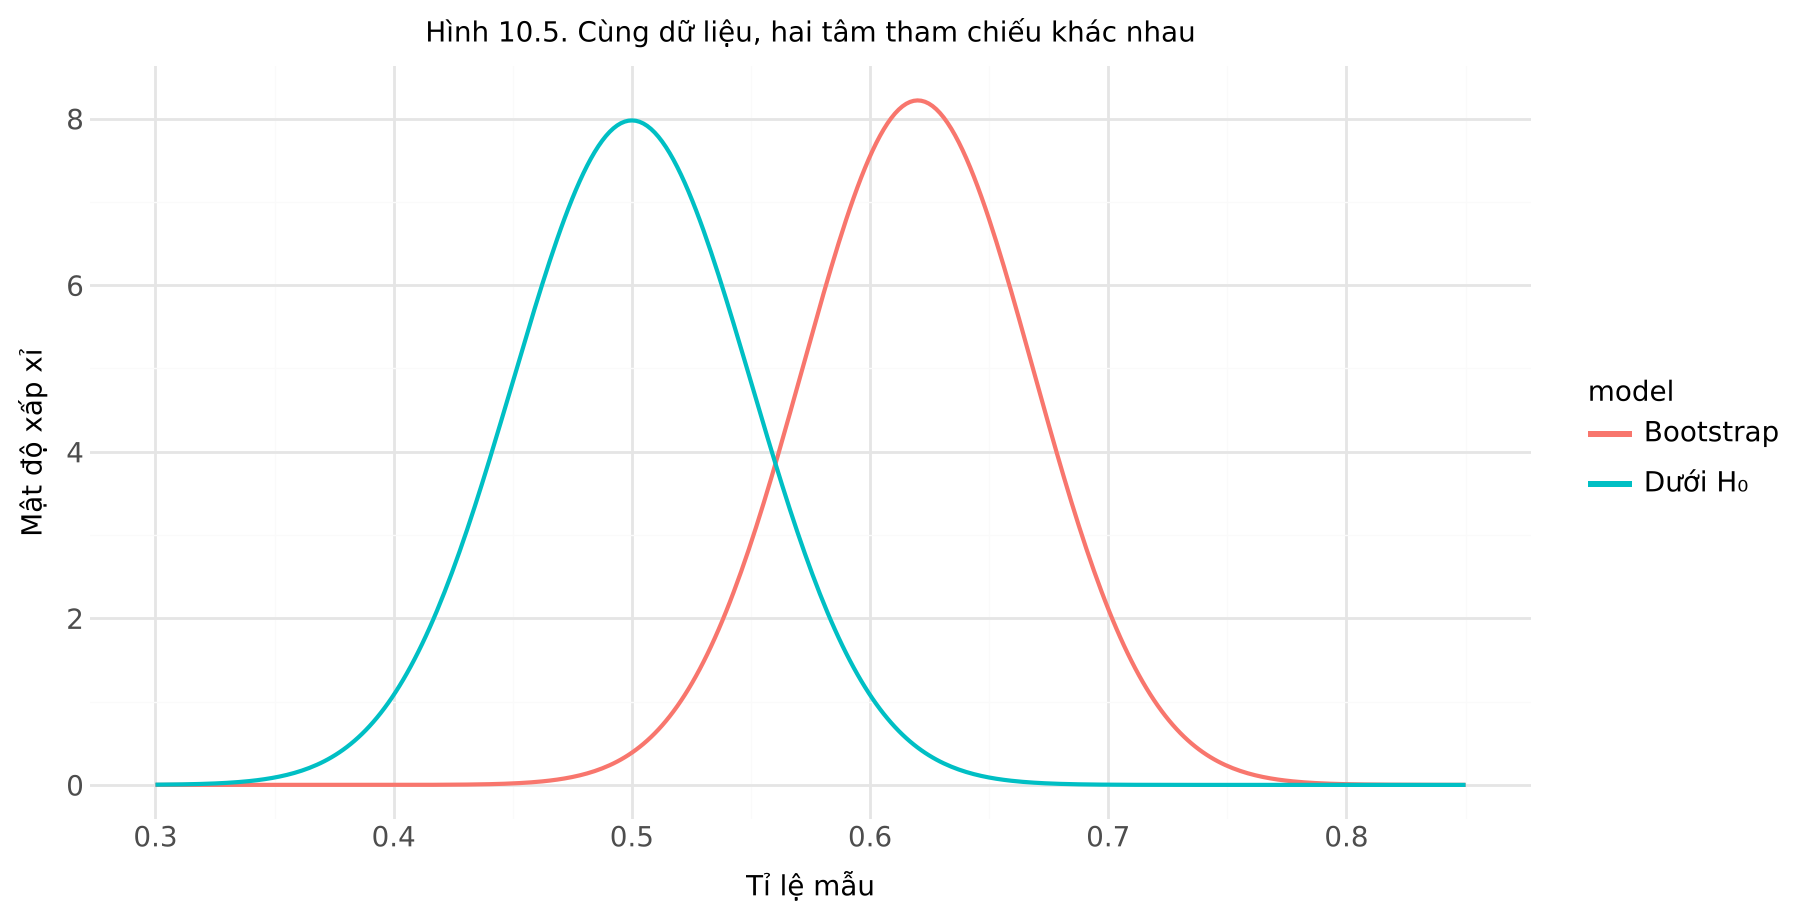

In [12]:
p = (ggplot(two_models, aes(x='p_hat', y='density', color='model'))
     + geom_line(size=0.85)
     + labs(title='Hình 10.5. Cùng dữ liệu, hai tâm tham chiếu khác nhau', x='Tỉ lệ mẫu', y='Mật độ xấp xỉ')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Không dùng phân phối bootstrap chưa điều chỉnh để tính giá trị p.** Phân phối bootstrap đặt tâm tại dữ liệu đã thấy, không tại $H_0$. Muốn kiểm định bằng bootstrap phải dịch phân phối về đúng $H_0$ trước; phần đó không thuộc buổi này.

### Luyện tập vận dụng — kiểm định tỉ lệ không dùng chuẩn

Một cơ sở đo 20 linh kiện khác nhau chọn ngẫu nhiên từ một lô mới, giả sử độc lập; 16 linh kiện đạt (tiêu thụ không quá 2,0 Wh). Mốc tham chiếu $p_0=0{,}5$. (1) Với câu hỏi “tỉ lệ đạt có cao hơn 50% không?”, viết $H_0$, $H_A$. (2) Tính xác suất nhị thức chính xác của 16 thành công trở lên. (3) Tính $np_0$; có nên dùng xấp xỉ chuẩn theo quy tắc $np_0,\ n(1-p_0)\ge10$ không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $H_0: p=0{,}5$, $H_A: p>0{,}5$.

*Câu 2.* $K\sim\operatorname{Binomial}(20;\ 0{,}5)$; mỗi dãy 20 kết quả có xác suất $2^{-20}$.
$$P(K\ge16)=\frac{\binom{20}{16}+\binom{20}{17}+\binom{20}{18}+\binom{20}{19}+\binom{20}{20}}{2^{20}}=\frac{4845+1140+190+20+1}{1\,048\,576}=\frac{6196}{1\,048\,576}\approx0{,}005909.$$
Với $\alpha=0{,}05$, bác bỏ $H_0$.

*Câu 3.* $np_0=n(1-p_0)=10$: vừa chạm ngưỡng. Quy tắc 10 không bảo đảm xấp xỉ đủ tốt; khi tính chính xác được thì dùng chính xác. (Thử: $Z=(0{,}8-0{,}5)/\sqrt{0{,}25/20}\approx2{,}68$, $P(Z\ge2{,}68)\approx0{,}0037$, nhỏ hơn giá trị chính xác khoảng 38%.)

</details>

In [13]:
print('P(K≥16):',stats.binom.sf(15,20,.5))

P(K≥16): 0.005908966064453125


### Sáu bước và bốn điều giá trị p không nói

1. **Mô tả dữ liệu**: đơn vị, biến kết quả, các nhóm và cỡ nhóm, cách thu thập hoặc gán nhóm.
2. **Phát biểu** $H_0$, $H_A$; chọn thống kê $T$ và hướng "cực đoan".
3. **Chọn cơ chế** dựng phân phối dưới $H_0$: mô hình xác suất, hoặc cách gán nhóm phù hợp với thiết kế.
4. **Dựng phân phối** dưới $H_0$: tính chính xác (công thức, liệt kê) hoặc mô phỏng theo cơ chế đã chọn.
5. **Tính xác suất đuôi**: xác suất $T$ ít nhất cực đoan như $t_{obs}$.
6. **Diễn giải**: dữ liệu hợp với $H_0$ đến đâu; nói rõ phạm vi và giới hạn.

Giá trị p **không** là:

- xác suất $H_0$ đúng sau khi đã thấy dữ liệu;
- xác suất của đúng kết quả quan sát (nó là xác suất của cả vùng ít nhất cực đoan như thế);
- bằng chứng $H_0$ đúng khi giá trị p lớn;
- thước đo độ lớn hay tầm quan trọng thực tế, hay bằng chứng nhân quả khi giá trị p nhỏ.

<a id="muc-4"></a>

## 4. Gán lại nhóm phải giữ đúng thiết kế

### Hai nhóm và thống kê chênh lệch

Khi mỗi đơn vị thuộc nhóm A hoặc B và có kết quả đạt/không đạt, thống kê tự nhiên là
$$T=\hat p_A-\hat p_B,\qquad t_{obs}=\hat p_{A, obs}-\hat p_{B, obs}.$$

| Câu hỏi | Thống kê thường dùng |
|---|---|
| Một tỉ lệ | $K$ hoặc $\hat p$ |
| Một trung bình | $\bar X$ |
| Hai tỉ lệ | $\hat p_A-\hat p_B$ |
| Hai trung bình | $\bar X_A-\bar X_B$ |

### Hai cách dựng phân phối dưới $H_0$

**Cách 1 — Từ mô hình xác suất.** Như bài 100 linh kiện: $H_0$ cho một mô hình cụ thể ($K\sim\operatorname{Binomial}(n, p_0)$), tính hoặc mô phỏng từ mô hình.

**Cách 2 — Từ thiết kế gán nhóm.** Nếu các đơn vị đã được **gán ngẫu nhiên** vào A/B, ta dùng chính phép gán ngẫu nhiên ấy làm nguồn ngẫu nhiên.

Giả thuyết dùng ở cách 2 là **giả thuyết không chặt chẽ** (sharp null): đổi A thành B không làm thay đổi kết quả của **bất kỳ đơn vị nào**. Nếu đúng như vậy, kết quả của mọi đơn vị đã biết hết, bất kể chúng ở nhóm nào. Thứ duy nhất ngẫu nhiên là **ai được gán vào A**. Vậy:

1. Giữ cố định kết quả của từng đơn vị.
2. Liệt kê (hoặc lấy ngẫu nhiên) các cách gán **đúng theo thiết kế**, ví dụ đúng 6 đơn vị vào A.
3. Với mỗi cách gán, tính lại $T$.
4. Giá trị p là tỉ lệ cách gán cho $T$ ít nhất cực đoan như $t_{obs}$.

Giả thuyết chặt chẽ mạnh hơn "$p_A=p_B$": nó nói về từng đơn vị, không chỉ về tỉ lệ trung bình.

**Khi nào được gán lại nhãn?**

- Thí nghiệm có gán ngẫu nhiên: được, vì phép gán lại mô phỏng đúng cơ chế đã sinh ra dữ liệu.
- Dữ liệu quan sát (không ai gán nhóm): chỉ được khi chấp nhận thêm giả định rằng nhãn nhóm "có thể hoán đổi"; giả định này cần lập luận riêng (xem mục 5).
- Dữ liệu cặp (đo trước–sau trên cùng đơn vị): không trộn nhãn tùy ý trên mọi dòng; phải giữ cặp, chỉ hoán đổi bên trong mỗi cặp.

### Luyện tập cơ bản — lập giả thuyết và tính thống kê

Hai dây chuyền A và B sản xuất cùng loại bo mạch. Lấy ngẫu nhiên 60 sản phẩm khác nhau từ mỗi dây chuyền, giả sử độc lập. Sản phẩm lỗi nếu không qua phép thử nguồn điện tiêu chuẩn: A có 18 lỗi, B có 12. (1) Tính tỉ lệ lỗi hai dây chuyền và $t_{obs}=\hat p_A-\hat p_B$. (2) Viết $H_0$, $H_A$ cho câu hỏi “tỉ lệ lỗi của A có cao hơn B không?”. (3) Nếu dùng thước đo hiệu số sản phẩm lỗi, giá trị quan sát bằng bao nhiêu? (Chưa yêu cầu tính giá trị p.)

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $\hat p_A=18/60=0{,}30$, $\hat p_B=12/60=0{,}20$; $t_{obs}=0{,}10$.

*Câu 2.* Với $p_A, p_B$ là tỉ lệ lỗi của tổng thể sản phẩm hai dây chuyền: $H_0: p_A=p_B$, $H_A: p_A>p_B$.

*Câu 3.* $18-12=6$ sản phẩm. Vì hai mẫu cùng cỡ 60, $6=60\times0{,}10$: hai thước đo tăng giảm cùng nhau và cho cùng giá trị p.

Chưa tính được giá trị p vì chưa nói phân phối của $T$ khi $H_0$ đúng được dựng thế nào. Đây là hai mẫu độc lập lấy từ hai dây chuyền, không phải một phép gán ngẫu nhiên; cách dựng phân phối cho tình huống này thuộc Tuần 11.

</details>

### Thí nghiệm 12 cảm biến — bài toán gán lại

Một nhóm kỹ thuật so sánh hai thuật toán hiệu chỉnh trên 12 cảm biến nhiệt cùng lô. A là thuật toán mới, B là thuật toán đang dùng. Mỗi cảm biến chỉ nhận một thuật toán. Cảm biến **đạt** nếu cả 10 phép đo đều có sai số tuyệt đối không quá 0,5°C so với nhiệt kế tham chiếu. Trước khi đo, chọn ngẫu nhiên đều 6 trong 12 cảm biến dùng A, 6 cảm biến còn lại dùng B.

Kết quả: A đạt 5/6, B đạt 2/6. Nếu đổi thuật toán không làm thay đổi kết quả của bất kỳ cảm biến nào, thì riêng phép gán ngẫu nhiên có dễ tạo ra chênh lệch như vậy không?

(1) Có bao nhiêu cách gán đồng khả năng? (2) Viết $T$ theo $K$ = số cảm biến đạt được gán vào A. (3) Lập bảng phân phối của $K$ và tính giá trị p một phía cho câu hỏi “A có làm tăng tỉ lệ đạt?”. (4) Kết luận với $\alpha=0{,}05$.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Mỗi cách gán là một cách chọn 6 trong 12 cảm biến vào A: $\binom{12}6=924$ cách, mỗi cách xác suất $1/924$. Không phải $2^{12}$ vì cỡ mỗi nhóm được cố định 6–6.

*Câu 2.* Dưới giả thuyết chặt chẽ, 7 kết quả đạt và 5 không đạt là cố định. Nếu A nhận $k$ cảm biến đạt thì B nhận $7-k$:
$$T(k)=\frac k6-\frac{7-k}6=\frac{2k-7}6,\qquad t_{obs}=T(5)=\frac36=0{,}5.$$

*Câu 3.* Số cách chọn đúng $k$ cảm biến đạt vào A là $N(k)=\binom7k\binom5{6-k}$.

| $k$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $N(k)$ | $7\cdot1=7$ | $21\cdot5=105$ | $35\cdot10=350$ | $35\cdot10=350$ | $21\cdot5=105$ | $7\cdot1=7$ |
| $T(k)$ | $-5/6$ | $-1/2$ | $-1/6$ | $1/6$ | $1/2$ | $5/6$ |

Kiểm tra: $7+105+350+350+105+7=924$. ($k=0$ không xảy ra vì B chỉ có 6 chỗ cho 7 cảm biến đạt.) Đây chính là phân phối siêu bội $K\sim\operatorname{Hypergeom}(N=12,\ D=7,\ n=6)$.

Vùng ít nhất thuận lợi cho A như quan sát là $T\ge0{,}5$, tức $K\ge5$:
$$\text{giá trị p}=\frac{105+7}{924}=\frac{112}{924}=\frac4{33}\approx0{,}1212.$$

*Câu 4.* $0{,}1212>0{,}05$: **không bác bỏ** $H_0$. Chưa đủ bằng chứng ở mức này để nói A cải thiện tỉ lệ đạt. Điều này **không** chứng minh A và B như nhau: với chỉ 6 cảm biến mỗi nhóm, ngay cả một cải thiện thật cũng khó phát hiện.

Mỗi cảm biến được đo 10 lần, nhưng đơn vị được gán thuật toán là **cảm biến**, nên cỡ mẫu là 12, không phải 120.

</details>

### Tự thực hiện một lần gán lại nhãn

Đánh số 12 cảm biến sao cho khớp với kết quả quan sát: cảm biến 1–5 ở A và đạt, cảm biến 6 ở A và không đạt, 7–8 ở B và đạt, 9–12 ở B và không đạt. Các cảm biến đạt là $\{1,2,3,4,5,7,8\}$ và được giữ cố định. Tính $T$ cho hai cách gán giả định: A $=\{1,2,3,6,9,10\}$ và A $=\{1,2,3,4,7,8\}$.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Cách gán thứ nhất.* A $=\{1,2,3,6,9,10\}$ chứa 3 cảm biến đạt (1, 2, 3). B có $7-3=4$ đạt. $T=3/6-4/6=-1/6$.

*Cách gán thứ hai.* A $=\{1,2,3,4,7,8\}$ chứa 6 cảm biến đạt. B có $7-6=1$ đạt. $T=6/6-1/6=5/6$.

Cả hai hợp lệ vì mỗi cách chọn đúng 6 cảm biến khác nhau vào A, không lặp và không bỏ sót. Đây là điểm khác bootstrap: ở bootstrap một cảm biến có thể bị chọn hai lần; ở đây mỗi cảm biến nhận **đúng một** nhãn, luôn có đúng 6 nhãn A và 6 nhãn B. Phương pháp mô phỏng phải phản ánh đúng cơ chế ngẫu nhiên đã sinh ra dữ liệu.

</details>

Ô dưới liệt kê **đủ 924 cách gán** bằng `combinations(range(12), 6)` (mỗi phần tử là một bộ 6 chỉ số vào A), tính $T$ cho từng cách, rồi đếm tỉ lệ $T\ge t_{obs}$. Dòng `stats.hypergeom.sf(4, 12, 7, 6)` tính $P(K\ge5)$ bằng công thức siêu bội. Phần `- 1e-12` để tránh sai số làm tròn khi so hai số thực bằng nhau.

**Bạn đoán trước:** hai cách có cho cùng 0,1212 không?

In [14]:
from itertools import combinations
sensor = np.array([1]*5+[0]+[1]*2+[0]*4)
assignments = list(combinations(range(12),6))
T0 = np.array([(2*sensor[list(a)].sum()-7)/6 for a in assignments])
t_obs = 5/6-2/6
print('Liệt kê:',len(T0),'p:',np.mean(T0>=t_obs-1e-12))
print('Siêu bội:',stats.hypergeom.sf(4,12,7,6))
k_sensor=np.arange(1,7)
sensor_pmf=pd.DataFrame({'difference':(2*k_sensor-7)/6,
    'probability':stats.hypergeom.pmf(k_sensor,12,7,6),
    'region':np.where(k_sensor>=5,'T ≥ 0,5','Còn lại')})
display(pd.DataFrame({'K':k_sensor,'Số cách':[7,105,350,350,105,7],'T':(2*k_sensor-7)/6}))
assert len(T0)==924 and np.isclose(np.mean(T0>=t_obs-1e-12),4/33)

Liệt kê: 924 p: 0.12121212121212122
Siêu bội: 0.1212121212121212


,K,Số cách,T
0,1,7,-0.83333
1,2,105,-0.50000
2,3,350,-0.16667
3,4,350,0.16667
4,5,105,0.50000
5,6,7,0.83333


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(sensor_pmf, aes(...))` lấy bảng `sensor_pmf`; trong `aes`, trục ngang là cột `difference`, trục đứng là cột `probability`. `fill='region'` cho mỗi giá trị của cột `region` một màu riêng. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau.

**Đọc hình.** Chỉ có 6 giá trị $T$ khả dĩ. Phân phối đối xứng quanh 0 vì dưới $H_0$ nhãn A và B hoán đổi được. Hai cột màu khác ($T=1/2$ và $T=5/6$) cộng lại thành giá trị p 0,1212. Hình này dựng từ phép đếm chính xác, không phải mô phỏng.

<!-- branch-plot-instructions: end -->

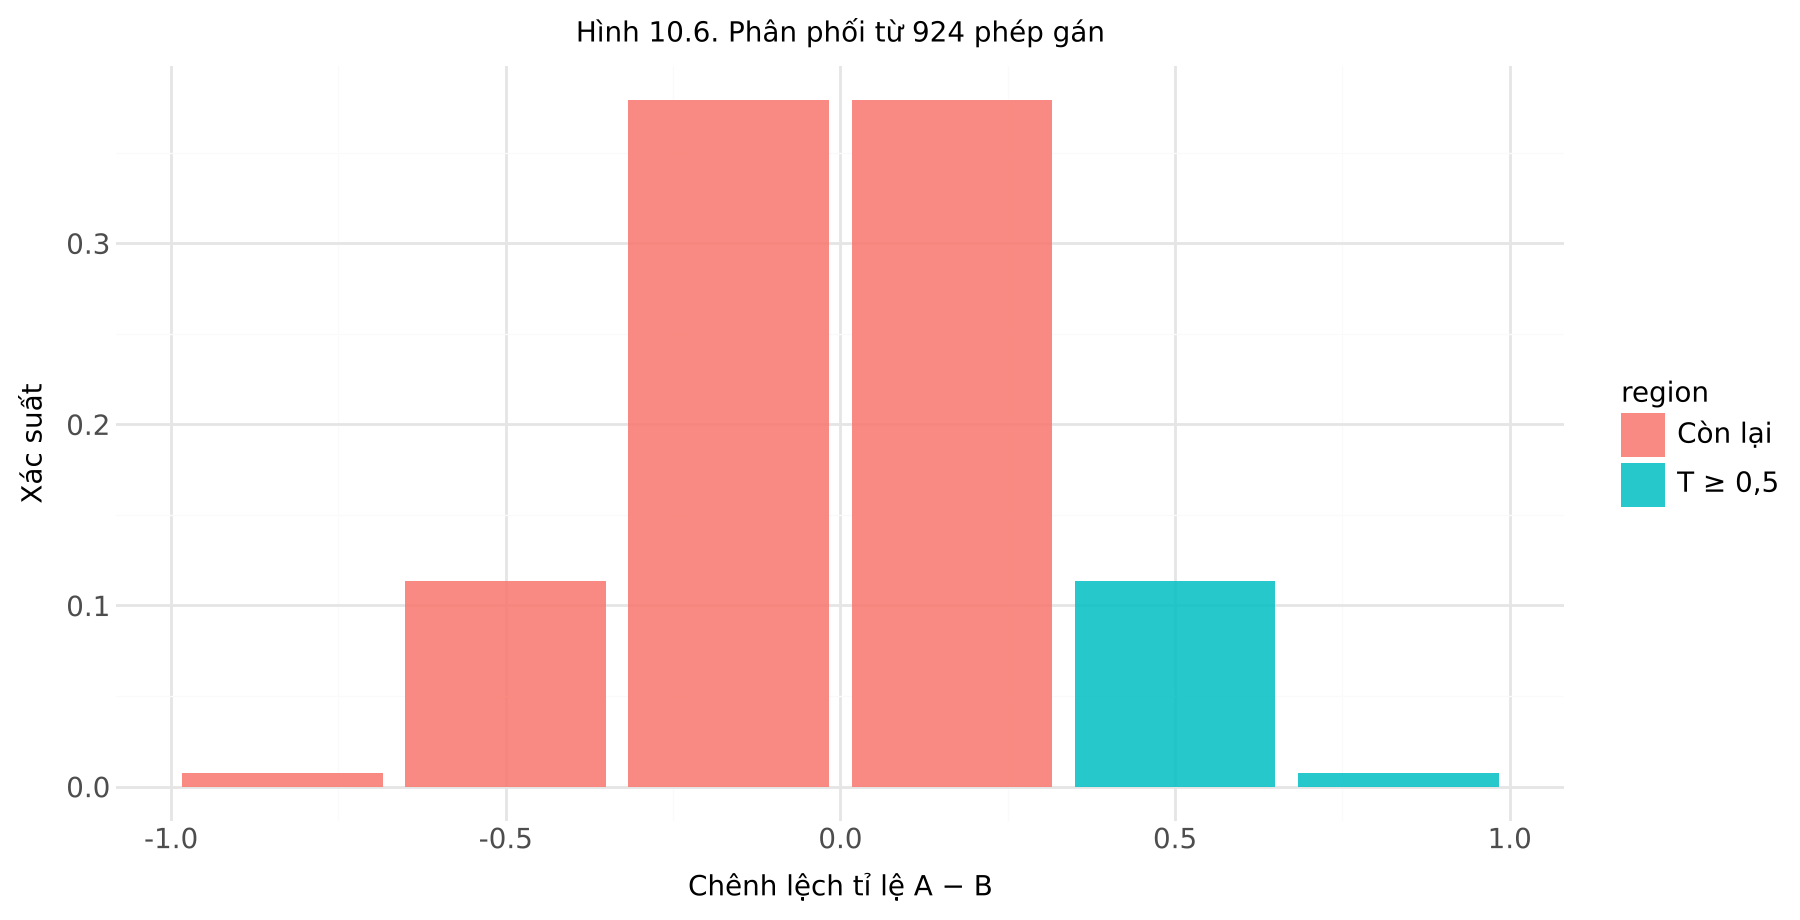

In [15]:
p = (ggplot(sensor_pmf, aes(x='difference', y='probability', fill='region'))
     + geom_col(position='dodge', alpha=0.85)
     + labs(title='Hình 10.6. Phân phối từ 924 phép gán', x='Chênh lệch tỉ lệ A − B', y='Xác suất')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Liệt kê và công thức cho cùng $4/33$. Khi liệt kê hết được, không cần mô phỏng.

### Cùng cơ chế, đổi thống kê: hai trung bình

| | 12 cảm biến | 6 thiết bị (bài dưới) |
|---|---|---|
| Kết quả đo | đạt/không đạt (0/1) | thời gian xử lý (ms) |
| Thống kê | $\hat p_A-\hat p_B$ | $\bar X_A-\bar X_B$ |
| Cơ chế gán | ngẫu nhiên 6–6 | ngẫu nhiên 3–3 |
| Số phép gán | $\binom{12}6=924$ | $\binom63=20$ |

Đổi loại biến kết quả không đổi cơ chế gán nhóm; chỉ đổi thống kê và cách tính.

### Bài 6 thiết bị, so sánh hai trung bình

Sáu thiết bị được gán ngẫu nhiên 3–3. Thời gian xử lý (ms): A: 8, 9, 10; B: 11, 12, 13. Câu hỏi định trước: A có giảm thời gian không? Dưới giả thuyết chặt chẽ (đổi cấu hình không đổi thời gian của từng thiết bị), dùng $T=\bar X_A-\bar X_B$. Tính $t_{obs}$, số phép gán, giá trị p một phía và hai phía.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Thống kê quan sát.* $t_{obs}=9-12=-3$ ms.

*Số phép gán.* $\binom63=20$, đồng khả năng.

*Viết $T$ theo tổng.* Tổng sáu thời gian là 63. Gọi $S_A$ là tổng ba thời gian ở A, thì B có tổng $63-S_A$:
$$T=\frac{S_A}3-\frac{63-S_A}3=\frac{2S_A-63}3.$$
$T\le-3$ khi và chỉ khi $S_A\le27$. Tổng nhỏ nhất của ba số trong $\{8,\ldots,13\}$ là $8+9+10=27$, và chỉ bộ này đạt được.

*Giá trị p.* Một phía (A nhanh hơn): $1/20=0{,}05$. Hai phía theo $|T|\ge3$: có thêm bộ $\{11,12,13\}$ cho $T=+3$, nên $2/20=0{,}10$.

*Kết luận.* Với quy tắc "bác bỏ khi giá trị p $\le\alpha=0{,}05$", kiểm định một phía vừa đúng ngưỡng bác bỏ; kiểm định hai phía thì không. Đây là lý do hướng của $H_A$ phải chọn **trước**. Với chỉ 6 thiết bị, giá trị p nhỏ nhất có thể đạt được là $1/20$.

</details>

In [16]:
times = np.arange(8,14)
T6 = np.array([times[list(a)].mean()-np.delete(times,list(a)).mean()
               for a in combinations(range(6),3)])
print('20 phép gán:',len(T6),'p trái:',np.mean(T6<=-3+1e-12),
      'p hai phía:',np.mean(np.abs(T6)>=3-1e-12))

20 phép gán: 20 p trái: 0.05 p hai phía: 0.1


<a id="muc-5"></a>

## 5. Kristen Gilbert: kiểm định mô hình liên hệ có điều kiện

### Bối cảnh

Tại một trung tâm y tế ở Northampton, Massachusetts, nhân viên nhận thấy tỉ lệ ca trực có bệnh nhân tử vong khác nhau giữa các ca có và không có điều dưỡng Kristen Gilbert. Dữ liệu được chia theo Gilbert có mặt hay không trong ca.

Đây là **nghiên cứu quan sát**: không ai gán ngẫu nhiên nhân viên vào ca trực. Theo STAT 20, mối liên hệ thống kê này đã không được tòa án dùng khi phán quyết, vì nó không đủ để xác định cơ chế gây tử vong hay trách nhiệm pháp lý.

### Dữ liệu

| staff | death = yes | death = no | Tổng |
|---|---|---|---|
| gilbert | 40 | 217 | 257 |
| no_gilbert | 34 | 1.350 | 1.384 |
| Tổng | 74 | 1.567 | 1.641 |

- **Đơn vị là một ca trực**, không phải một bệnh nhân. Kết quả là "ca có ít nhất một tử vong".
- Tệp CSV được **tái dựng** từ bảng trên: tạo đúng số dòng cho mỗi ô rồi trộn thứ tự bằng seed cố định. Cột `shift` chỉ là mã dòng giả lập, không phải thời gian. Tệp không phải hồ sơ gốc, nên không có thông tin về người bệnh, thời điểm hay yếu tố gây nhiễu.

### Giả thuyết và thống kê

Câu hỏi: tỉ lệ ca có tử vong có **khác nhau** giữa ca có và không có Gilbert?
$$H_0: p_G=p_K,\qquad H_A: p_G\ne p_K,\qquad T=\hat p_G-\hat p_K.$$
$$t_{obs}=\frac{40}{257}-\frac{34}{1384}\approx0{,}1556-0{,}0246=0{,}1311.$$
Chênh lệch quan sát là 13,11 điểm phần trăm (tính trên ca trực).

### Phân phối dưới $H_0$

Không có phép gán ngẫu nhiên, nên phải **giả định** rằng dưới $H_0$ nhãn "có tử vong" có thể hoán đổi giữa các ca: 74 ca có tử vong là một nhóm ngẫu nhiên trong 1.641 ca, không liên quan đến ai trực. Với giả định này, giữ cố định 74 ca có tử vong và hai cỡ nhóm 257, 1.384. Số ca có tử vong rơi vào nhóm Gilbert là
$$K\sim\operatorname{Hypergeom}(N=1641,\ D=74,\ n=257),\qquad T(K)=\frac K{257}-\frac{74-K}{1384}.$$
Đây là cùng lập luận với 12 cảm biến, chỉ khác là "nhãn hoán đổi được" giờ là giả định, không do thiết kế bảo đảm.

Giá trị p hai phía theo trị tuyệt đối:
$$\text{giá trị p}=P_{H_0}\big(|T(K)|\ge|t_{obs}|\big)\approx4{,}306\times10^{-15}.$$

### Kết luận

- **Thống kê, có điều kiện:** nếu giả định hoán đổi nhãn giữa các ca là phù hợp, dữ liệu cho bằng chứng rất mạnh chống $H_0$ "không có liên hệ giữa staff và death".
- **Giới hạn:** mức bệnh của bệnh nhân, ca ngày hay ca đêm, cách xếp lịch... đều có thể khác giữa các ca của Gilbert và các ca khác, và đều có thể ảnh hưởng tỉ lệ tử vong.
- **Không được kết luận:** sự có mặt của Gilbert **gây ra** tử vong, hay xác định trách nhiệm pháp lý.

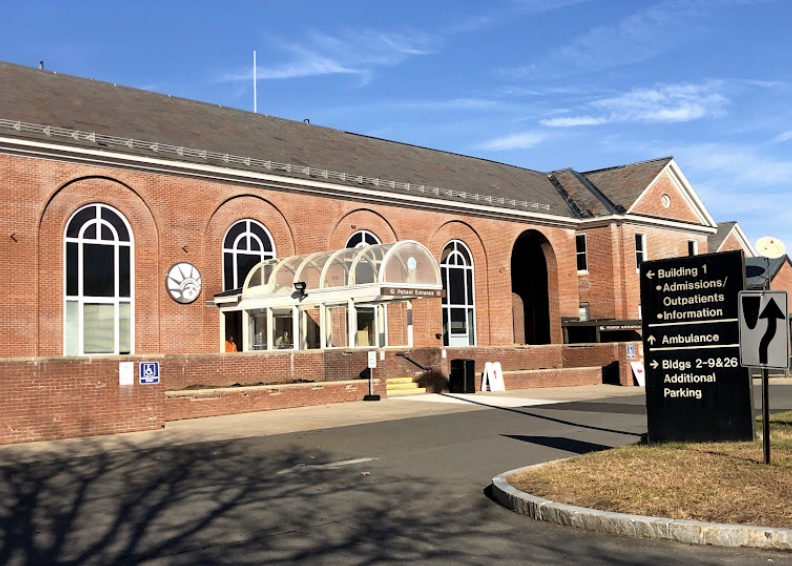

*Hình tham khảo 10.21: Trung tâm y tế trong tình huống của học liệu. Nguồn: STAT 20 bản dịch tiếng Việt, mục 5.4, hình nhúng trong học liệu gốc.*

Ảnh cho bối cảnh của ví dụ. Mọi phép tính bên dưới chỉ dựa vào bảng 2×2.

Ô dưới làm bốn việc:

1. đọc CSV và lập lại bảng 2×2 bằng `pd.crosstab` (đối chiếu với bảng trên);
2. tính giá trị p chính xác: với mọi $k=0,\ldots,74$ tính $T(k)$ và $P(K=k)$ theo siêu bội, rồi cộng xác suất của các $k$ có $|T(k)|\ge|t_{obs}|$;
3. mô phỏng 500 lần hoán vị như slide: `r_g.hypergeometric(74, 1567, 257, size=500)` sinh trực tiếp số ca có tử vong rơi vào nhóm Gilbert trong mỗi lần hoán vị;
4. đếm số lần mô phỏng ít nhất cực đoan như quan sát.

**Bạn đoán trước:** trong 500 lần mô phỏng, có lần nào cho $|T|\ge0{,}131$ không?

In [17]:
gilbert = pd.read_csv(DATA/'kristen_gilbert_reconstructed.csv')
table = pd.crosstab(gilbert.staff,gilbert.death).reindex(index=['gilbert','no_gilbert'],columns=['yes','no'])
display(table)
ng,nk=257,1384
t_g=40/ng-34/nk
possible=np.arange(75)
t_possible=possible/ng-(74-possible)/nk
prob=stats.hypergeom.pmf(possible,1641,74,ng)
p_g=prob[np.abs(t_possible)>=abs(t_g)-1e-12].sum()
r_g=np.random.default_rng(20261101)
sim_g=r_g.hypergeometric(74,1567,ng,size=500)
sim_t=sim_g/ng-(74-sim_g)/nk
extreme=np.sum(np.abs(sim_t)>=abs(t_g)-1e-12)
print('Chênh lệch:',t_g,'=',100*t_g,'điểm phần trăm')
print('p chính xác:',p_g,'; số cực đoan/500:',extreme)
print('Ước lượng Monte Carlo có hiệu chỉnh:',(extreme+1)/(len(sim_t)+1))
gilbert_null=pd.DataFrame({'difference':sim_t})
assert np.isclose(t_g,40/257-34/1384)

death,yes,no
staff,,
gilbert,40,217
no_gilbert,34,1350


Chênh lệch: 0.1310755493578642 = 13.10755493578642 điểm phần trăm
p chính xác: 4.3061271843935704e-15 ; số cực đoan/500: 0
Ước lượng Monte Carlo có hiệu chỉnh: 0.001996007984031936


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(gilbert_null, aes(...))` lấy bảng `gilbert_null`; trong `aes`, trục ngang là cột `difference`. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `t_g`.

**Đọc hình.** 500 chênh lệch mô phỏng dưới $H_0$ tụ quanh 0, trong khoảng chừng ±0,05. Đường đứt đoạn là $t_{obs}\approx0{,}131$, nằm rất xa bên phải mọi cột.

<!-- branch-plot-instructions: end -->

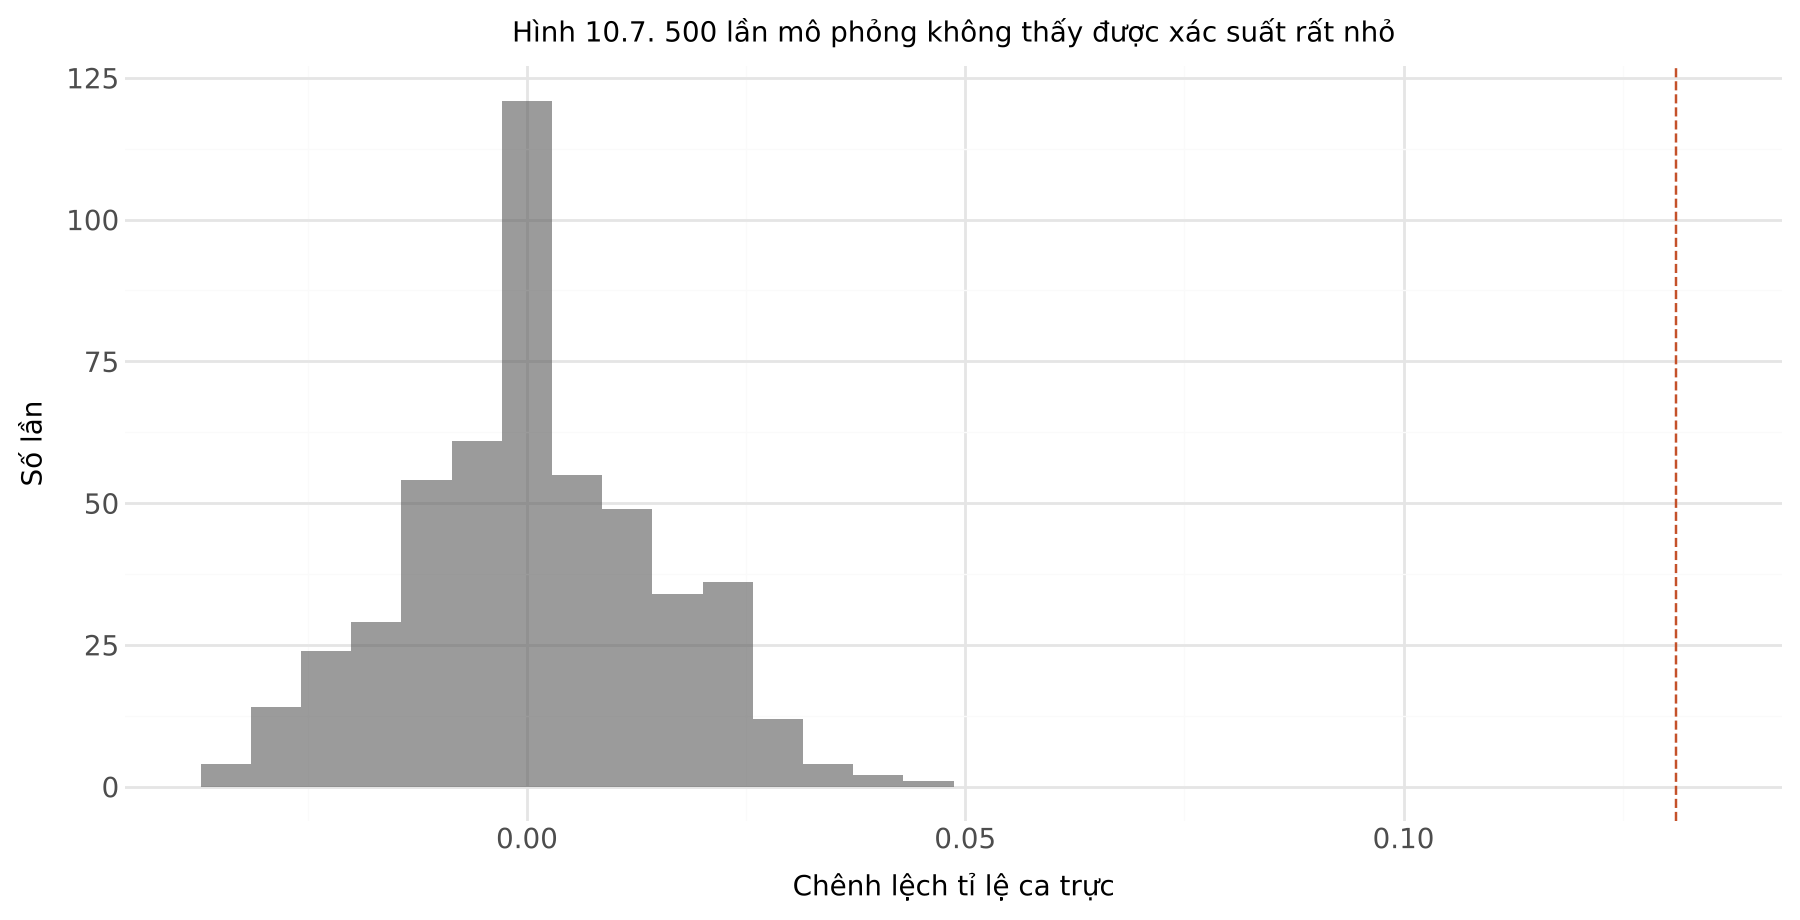

In [18]:
p = (ggplot(gilbert_null, aes(x='difference'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=t_g, linetype='dashed', color='#C4512A')
     + labs(title='Hình 10.7. 500 lần mô phỏng không thấy được xác suất rất nhỏ', x='Chênh lệch tỉ lệ ca trực', y='Số lần')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** 0/500 lần mô phỏng ít nhất cực đoan như quan sát, trong khi giá trị p chính xác là $4{,}3\times10^{-15}$.

**0/500 không có nghĩa giá trị p bằng 0.** Với 500 lần mô phỏng, độ phân giải chỉ cỡ $1/500=0{,}002$: mọi xác suất nhỏ hơn mức đó đều có thể cho 0 lần. Vì vậy khi báo cáo giá trị p từ mô phỏng, người ta thường dùng $(b+1)/(B+1)$, với $b$ là số lần cực đoan: ở đây $1/501\approx0{,}002$. Con số này chỉ là cận trên thận trọng, không phải ước lượng của $4{,}3\times10^{-15}$; muốn biết đuôi nhỏ như vậy phải tính bằng công thức siêu bội.

**Không gấp đôi một phía.** Phân phối của $T$ ở đây không đối xứng quanh 0 (hai nhóm cỡ rất khác nhau, 257 và 1.384), nên giá trị p hai phía phải tính thẳng theo $|T|$, như ô trên đã làm.

<a id="muc-6"></a>

## 6. Bài toán tổng hợp: tính đúng chưa đủ để kết luận đúng

Năm bài dưới đây kiểm tra hai kỹ năng cùng lúc: tính đúng, và biết phép tính ấy **cho phép** kết luận đến đâu. Với mỗi bài, trước khi mở đáp án, hãy tự nêu: mô hình hay cơ chế ngẫu nhiên nào được dùng, và kết luận áp dụng cho tổng thể nào. Các số trong bài là dữ kiện giả định của slide.

### Bài toán thử thách A — sai lệch do chọn mẫu

Một khóa học có 12.000 người đăng ký. Có 4.000 phiếu trả lời từ những người khác nhau đã hoàn thành; mọi phiếu đều ghi “hoàn thành”. Số người hoàn thành thực tế trong 12.000 người chưa biết. (1) Tính tỉ lệ quan sát và sai số chuẩn bootstrap. (2) Từ dữ kiện chắc chắn rằng 4.000 người khác nhau đã hoàn thành, tỉ lệ của cả khóa có thể nằm trong khoảng nào? (3) Nếu hệ thống cho biết đúng 6.000 người hoàn thành, sai lệch của tỉ lệ khảo sát là bao nhiêu? Đề xuất cách lấy số liệu tốt hơn.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $\hat p=4000/4000=1$. Mọi mẫu bootstrap toàn số 1, nên $SE_{boot}=\sqrt{1\times0/4000}=0$.

*Câu 2.* Ít nhất 4.000 trong 12.000 người đã hoàn thành, nhiều nhất là tất cả: $p\in[1/3;\ 1]$.

*Câu 3.* $p=6000/12\,000=0{,}5$; sai lệch $\hat p-p=1-0{,}5=0{,}5$.

SE bằng 0 nhưng sai lệch tới 0,5. SE chỉ đo biến thiên do lấy mẫu; nó hoàn toàn không thấy chệch chọn mẫu. Cách tốt hơn: lấy mẫu từ danh sách **tất cả** 12.000 người đăng ký (kể cả người chưa hoàn thành), hoặc dùng thống kê hành chính đầy đủ của hệ thống.

</details>

### Bài toán thử thách B — chọn phương án so sánh

Một trung tâm kỹ thuật thử hai cấu hình A và B trên 8 bộ điều khiển cùng loại; chọn ngẫu nhiên đều 4 bộ chạy A, 4 bộ chạy B. Thời gian hoàn thành (ms): A: 8, 9, 10, 11; B: 12, 13, 14, 15. Câu hỏi định trước: A có làm giảm thời gian không? (1) Chọn thống kê và tính giá trị quan sát. (2) Giả sử thời gian của từng bộ không đổi theo cấu hình; từ đúng cơ chế gán 4–4, tính xác suất tạo ra kết quả ít nhất thuận lợi cho A như quan sát. (3) Nếu không gán ngẫu nhiên mà chọn 4 máy cũ vào A, 4 máy mới vào B, câu 2 còn đủ cơ sở nói về hiệu quả của A không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* $T=\bar X_A-\bar X_B$; $t_{obs}=9{,}5-13{,}5=-4$ ms.

*Câu 2.* Tổng 8 thời gian là 92 ms; có $\binom84=70$ cách gán đồng khả năng. Với $S_A$ là tổng ở A:
$$T=\frac{S_A}4-\frac{92-S_A}4=\frac{S_A-46}2.$$
$T\le-4$ khi $S_A\le38$. Tổng nhỏ nhất của 4 số trong $\{8,\ldots,15\}$ là $8+9+10+11=38$, và chỉ bộ này đạt. Giá trị p $=1/70\approx0{,}0143$.

*Câu 3.* Không. Nếu A toàn máy cũ và B toàn máy mới, tuổi máy có thể làm A chậm hay nhanh, lẫn với tác động của cấu hình. Khi không có phép gán ngẫu nhiên, việc gán lại nhãn không còn mô phỏng cơ chế thật nào, nên con số 1/70 không có cơ sở và không suy ra được tác động nhân quả.

</details>

### Bài toán — chứng minh hay bác bỏ?

Một nhóm chỉ khảo sát những sinh viên đã hoàn thành khóa học, thu được 1.000 câu trả lời, tất cả ghi “đã hoàn thành”. Nhóm tạo một triệu mẫu bootstrap và báo cáo khoảng tin cậy 95% là $[1;\ 1]$. Chứng minh hoặc bác bỏ: “Lặp bootstrap đủ nhiều lần sẽ khắc phục được mọi sai lệch do chọn mẫu ban đầu.” Nêu một tổng thể cụ thể phù hợp với dữ kiện.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

**Bác bỏ** bằng phản ví dụ. Xét tổng thể 10.000 sinh viên, chỉ 3.000 người hoàn thành; danh sách khảo sát chỉ chứa người hoàn thành.

- Tỉ lệ thật: $p=3000/10\,000=0{,}30$.
- Tỉ lệ trong mẫu: $\hat p=1$.
- Mọi mẫu bootstrap toàn giá trị 1, nên khoảng phân vị là $[1;\ 1]$ dù lặp một triệu hay một tỉ lần.

Khoảng không chứa $p=0{,}30$, nên phát biểu sai. Số lần lặp chỉ quyết định độ chính xác của **mô phỏng**; nó không thể khôi phục những người đã bị loại khỏi khung lấy mẫu.

</details>

### Luyện tập — nhận diện sai lầm diễn giải

Hai kiểm định độc lập có giá trị p 0,03 và 0,80 (đã cho sẵn). Một nghiên cứu thứ ba kiểm tra tỉ lệ xử lý đúng tín hiệu: $H_0: p=0{,}500$, $H_A: p>0{,}500$; trong 1.000.000 tín hiệu độc lập có 502.000 tín hiệu đúng; giá trị p nhị thức chính xác xấp xỉ 0,0000318. (1) Nếu $H_0$ của kiểm định thứ nhất đúng, trong 1.000 lần mô phỏng độc lập dự kiến bao nhiêu kết quả ít nhất cực đoan như quan sát? (2) Tương tự với giá trị p 0,80. (3) Tính $\hat p$ của nghiên cứu thứ ba và độ lệch khỏi $p_0$ theo điểm phần trăm. Các con số này có cho biết xác suất $H_0$ đúng hay mức quan trọng thực tế không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Mỗi lần mô phỏng dưới $H_0$ rơi vào vùng cực đoan với xác suất 0,03, nên số lần là nhị thức với kỳ vọng $1000\times0{,}03=30$.

*Câu 2.* $1000\times0{,}80=800$. Không suy ra được "$H_0$ đúng với xác suất 80%".

*Câu 3.* $\hat p=502\,000/1\,000\,000=0{,}502$; độ lệch $0{,}002$, tức **0,2 điểm phần trăm**. Giá trị p rất nhỏ vì $n$ rất lớn: với một triệu tín hiệu, $SE_{H_0}=\sqrt{0{,}25/10^6}=0{,}0005$, nên 0,002 đã là 4 SE. Nhưng 0,2 điểm phần trăm có đáng kể trong vận hành hay không là câu hỏi chuyên môn, giá trị p không trả lời được.

Cả ba con số là tần suất vùng đuôi **khi giả định $H_0$ đúng**, không phải xác suất $H_0$ đúng sau khi thấy dữ liệu.

</details>

### Bài toán diễn giải — bootstrap và phân phối dưới H₀

Từ mẫu 100 linh kiện ($n=100$, $K=62$): phân phối A là các tỉ lệ bootstrap, tâm ở 0,62, 95% phần giữa là $[0{,}52;\ 0{,}71]$; phân phối B sinh theo $H_0: p=0{,}50$, với $P_{H_0}(K\ge62)=0{,}01049$. (1) Tính bề rộng khoảng A và độ lệch quan sát so với tâm của B. (2) Nếu lặp 10.000 mẫu cỡ 100 từ $H_0$, dự kiến khoảng bao nhiêu mẫu có $K\ge62$? (3) Viết hai câu giải thích A và B trả lời hai câu hỏi khác nhau.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Câu 1.* Bề rộng A: $0{,}71-0{,}52=0{,}19$. Độ lệch so với tâm B: $0{,}62-0{,}50=0{,}12$.

*Câu 2.* $10\,000\times0{,}01049\approx104{,}9$, tức khoảng 105 mẫu.

*Câu 3.* A ước lượng độ biến thiên của $\hat p$ dựa trên mẫu đã thấy, dùng để lập khoảng tin cậy cho $p$. B mô tả $K$ dao động thế nào nếu $p=0{,}50$, dùng để tính độ hiếm của 62/100, tức giá trị p.

Cả hai phụ thuộc vào mô hình và thiết kế lấy mẫu; không cái nào sửa được chệch chọn mẫu hay tự chứng minh quan hệ nhân quả.

</details>

Ô dưới kiểm tra hai bài có phép tính dài: liệt kê 70 cách gán 4–4 của thử thách B, và tính giá trị p cho 502.000/1.000.000 tín hiệu.

In [19]:
times8=np.arange(8,16)
T8=np.array([times8[list(a)].mean()-np.delete(times8,list(a)).mean() for a in combinations(range(8),4)])
print('Thử thách B:',len(T8),'phép gán, p=',np.mean(T8<=-4+1e-12))
print('Tín hiệu: p-value=',stats.binomtest(502000,1000000,.5,alternative='greater').pvalue)
print('Độ lệch điểm phần trăm:',100*(502000/1000000-.5))
assert len(T8)==70 and np.isclose(np.mean(T8<=-4+1e-12),1/70)

Thử thách B: 70 phép gán, p= 0.014285714285714285
Tín hiệu: p-value= 3.1804668750394e-05
Độ lệch điểm phần trăm: 0.20000000000000018


### Khi nào được gán lại nhãn nhóm? Tóm lại

| Tình huống | Được gán lại? | Giữ cố định gì, thay đổi gì |
|---|---|---|
| Thí nghiệm 12 cảm biến (gán ngẫu nhiên 6–6) | Được | Giữ kết quả từng cảm biến; thay tập 6 cảm biến nhận A |
| Gilbert (nghiên cứu quan sát) | Chỉ khi chấp nhận giả định hoán đổi nhãn | Giữ 74 ca có tử vong và cỡ hai nhóm; hoán vị nhãn tử vong |
| Đo trước–sau trên cùng đơn vị | Không trộn tùy ý | Giữ cặp; chỉ hoán đổi “trước”/“sau” trong từng cặp, dưới giả định bổ sung |

Phép hoán vị phải khớp với thiết kế nghiên cứu và với $H_0$; không phải cách gán lại nhãn nào cũng có giá trị thống kê.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Bootstrap lấy mẫu lại **có hoàn lại** từ mẫu đã có để ước lượng SE và khoảng tin cậy. | Lấy không hoàn lại (SE ra 0); tưởng bootstrap tạo thêm dữ liệu. |
| SE bootstrap là độ lệch chuẩn của các $T^*_b$. | Lấy độ lệch chuẩn của dữ liệu gốc. |
| $B$ chỉ ảnh hưởng độ ổn định của mô phỏng; $n$ mới quyết định độ chính xác. | Tăng $B$ để "thu hẹp khoảng". |
| Bootstrap không sửa chệch chọn mẫu, phụ thuộc, mẫu quá nhỏ. | Tin khoảng $[1;\ 1]$ từ mẫu chỉ gồm người hoàn thành. |
| Kiểm định: $H_0$, $H_A$ (hướng chọn trước), $T$, phân phối dưới $H_0$, giá trị p, kết luận có phạm vi. | Chọn một phía sau khi nhìn dữ liệu. |
| Giá trị p = $P_{H_0}$(ít nhất cực đoan như quan sát). | Gọi giá trị p là "xác suất $H_0$ đúng"; chỉ tính $P(K=k_{obs})$. |
| Kiểm định tỉ lệ dùng $p_0$ cho SE; khoảng tin cậy dùng $\hat p$. | Dùng phân phối bootstrap (tâm $\hat p$) để tính giá trị p. |
| Gán lại nhãn phải theo đúng thiết kế: đúng cỡ nhóm, mỗi đơn vị một nhãn. | Hoán vị nhãn cho dữ liệu quan sát mà không nêu giả định. |
| Không bác bỏ $H_0$ ≠ $H_0$ đúng; giá trị p nhỏ ≠ tác động lớn hay nhân quả. | "Không bác bỏ nên A và B như nhau." |
| Mô phỏng $B$ lần không thấy được xác suất nhỏ hơn cỡ $1/B$. | Báo "p = 0" từ 0/500. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Vì sao bootstrap được lấy một quan sát nhiều lần, còn kiểm định 12 cảm biến không được lặp cảm biến?
2. Một kiểm định cho giá trị p 0,40. Bạn của bạn kết luận "vậy $H_0$ đúng". Bạn sửa câu này thế nào?
3. Trong một thí nghiệm có 10 đơn vị gán ngẫu nhiên 5–5, có bao nhiêu cách gán? Giá trị p một phía nhỏ nhất có thể đạt là bao nhiêu?
4. Trong bài 100 linh kiện, nếu $H_A: p\ne0{,}5$ và quan sát $K=40$, giá trị p bằng bao nhiêu?

<details><summary>Gợi ý đáp án</summary>

1. Bootstrap mô phỏng việc **lấy mẫu từ tổng thể**, nơi các lần rút gần như độc lập. Kiểm định ngẫu nhiên hóa mô phỏng **phép gán của thí nghiệm**, nơi mỗi cảm biến chỉ nhận một thuật toán và cỡ nhóm cố định 6–6.
2. "Dữ liệu không đủ bằng chứng để bác bỏ $H_0$." Giá trị p lớn có thể do $H_0$ đúng, hoặc do mẫu quá nhỏ để thấy khác biệt.
3. $\binom{10}5=252$ cách; giá trị p nhỏ nhất $1/252\approx0{,}004$.
4. $40$ cách 50 là 10, nên vùng cực đoan là $K\le40$ hoặc $K\ge60$. Phân phối đối xứng, nên giá trị p $=2P(K\le40)=2\times0{,}0284\approx0{,}057$.

</details>

**Buổi sau.** Tuần 11 mở rộng kiểm định sang hai trung bình (z, t gộp, Welch, t cặp), hai tỉ lệ, phương sai và bảng nhiều nhóm ($\chi^2$), rồi xét rủi ro của chính việc ra quyết định: sai lầm loại I, loại II và lực kiểm định. Ôn lại $H_0$, $H_A$, thống kê kiểm định, phân phối dưới $H_0$, giá trị p; tự trả lời “vì sao không bác bỏ $H_0$ không có nghĩa $H_0$ đúng?”.

## Nguồn học liệu

- Slide của học phần: `week10.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 5.3–5.4. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).